# 03 · Web 后端基础（Maven 基础）


来源：[飞书讲义《03-Web后端基础(Maven基础)》](https://heuqqdmbyk.feishu.cn/wiki/KTOKw4PvzipYeIkl3N5cSSxYnPb)。整理日期：2026-09-28。

本章从前端页面转入 Java 后端工程的基础工具：使用 Maven 统一项目目录、声明依赖、编译测试和打包，再用 JUnit 5 为业务方法编写单元测试。按原讲义顺序保留正文、10 段原代码、68 张配图/动图、3 张知识表格，以及 Maven 安装包与排错脚本附件入口。

需要操作的截图会配上关键文字或代码；影响理解与跟练的地方标注“补充”或“勘误”。第 5.6 节补齐原讲义没有完整给出的业务类、测试类与 POM，便于独立运行。图片已内嵌，可离线阅读；首次下载 Maven 依赖和打开外部资料仍需要网络。文中的盘符与安装路径是示例，请替换成自己的实际位置。


> 课程内容：
> 
> - 初始Maven
> - Maven概述
> 
>     - Maven模型
>     - Maven仓库介绍
>     - Maven安装与配置
> - IDEA集成Maven
> - 依赖管理
> - 单元测试


## 1 初始Maven


### 1.1 介绍

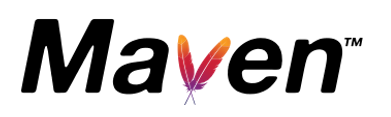

Maven 是一款用于管理和构建Java项目的工具，是Apache旗下的一个开源项目 。

> Apache 软件基金会，成立于1999年7月，是目前世界上最大的最受欢迎的开源软件基金会，也是一个专门为支持开源项目而生的非盈利性组织。
> 
> 开源项目：https://www.apache.org/index.html&#35;projects-list

那我们之前在JavaSE阶段，没有使用Maven，依然可以构建Java项目。 我们为什么现在还要学习Maven呢 ? 那接下来，我们就来聊聊Maven的作用。


### 1.2 Maven的作用

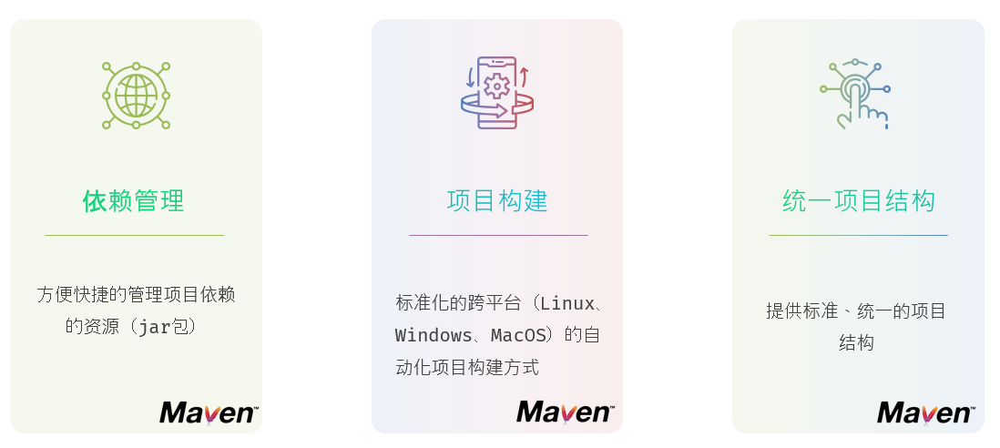


#### 1.2.1 依赖管理

方便快捷的管理项目依赖的资源(jar包)，避免版本冲突问题。

> **补充：**Maven 能统一声明、下载和选择依赖版本，但并不保证所有版本冲突自动消失。例如两个库要求同一组件的不同版本时，仍要查看依赖树、判断兼容性并调整版本；后面的“依赖传递”会说明。

<strong>1). 使用maven前</strong>

我们项目中要想使用某一个jar包，就需要把这个jar包从官方网站下载下来，然后再导入到项目中。然后在这个项目中，就可以使用这个jar包了。

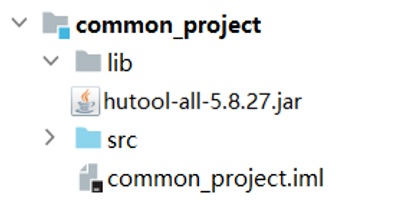

<strong>2). 使用maven后</strong>

当使用maven进行项目依赖(jar包)管理，则很方便的可以解决这个问题。 我们只需要在maven项目的pom.xml文件中，添加一段如下图所示的配置即可实现。

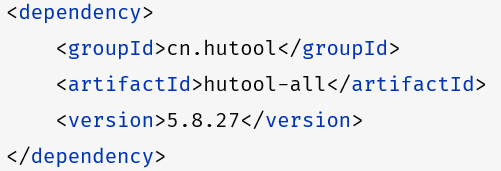

**配图配置转写：**下面的 `dependency` 放在 `pom.xml` 的 `dependencies` 中，表示需要 Hutool 的这个具体版本；版本沿用讲义示例。

```xml
<dependency>
    <groupId>cn.hutool</groupId>
    <artifactId>hutool-all</artifactId>
    <version>5.8.27</version>
</dependency>
```

在maven项目的配置文件中，加入上面这么一段配置信息之后，maven会自动的根据配置信息的描述，去下载对应的依赖。 然后在项目中，就可以直接使用了。


#### 1.2.2 项目构建

Maven还提供了标准化的跨平台的自动化构建方式。

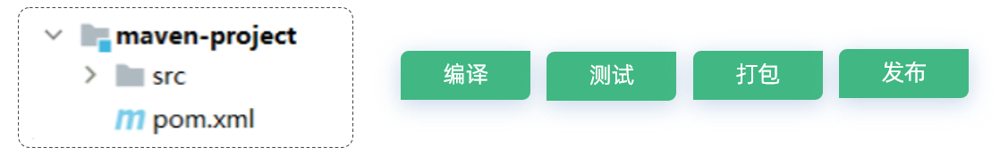

如上图所示我们开发了一套系统，代码需要进行编译、测试、打包、发布等过程，这些操作是所有项目中都需要做的，如果需要反复进行就显得特别麻烦，而Maven提供了一套简单的命令来完成项目构建。

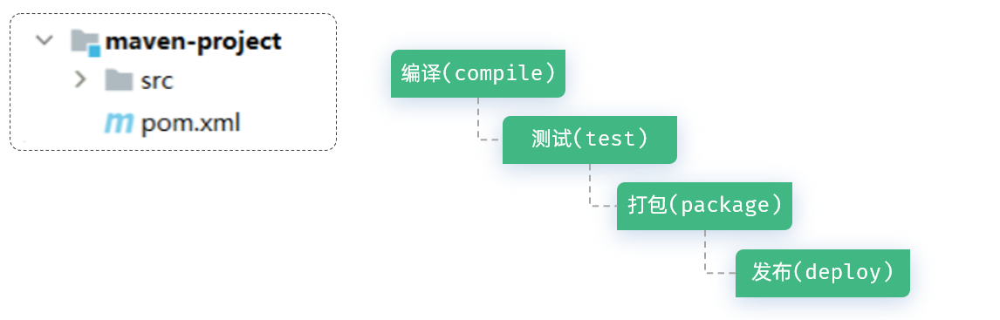

通过Maven中的命令，就可以很方便的完成项目的编译(compile)、测试(test)、打包(package)、发布(deploy) 等操作。 

> **勘误：**这里的 `deploy` 是将构建产物发布到**远程 Maven 仓库**，供其他项目引用；它本身不等于把 Web 应用启动到服务器上。

而且这些操作都是跨平台的，也就是说无论你是Windows系统，还是Linux系统，还是Mac系统，这些命令都是支持的。


#### 1.2.3 统一项目结构

Maven 还提供了标准、统一的项目结构 。

<strong>1). 未使用Maven</strong>

由于java的开发工具呢，有很多，除了大家熟悉的IDEA以外，还有像早期的Eclipse、MyEclipse。而不同的开发工具，创建出来的java项目的目录结构是存在差异的，那这就会出现一个问题。

Eclipse创建的java项目，并不能直接导入IDEA中。 IDEA创建的java项目，也没有办法直接导入到Eclipse中。

> **补充：**这句话强调各 IDE 的项目配置并不完全相同。IDEA、Eclipse 也有其他项目导入/转换功能，并非绝对不能互相导入。使用 `pom.xml` 作为共同的项目描述，能更稳定地重建依赖和编译配置。

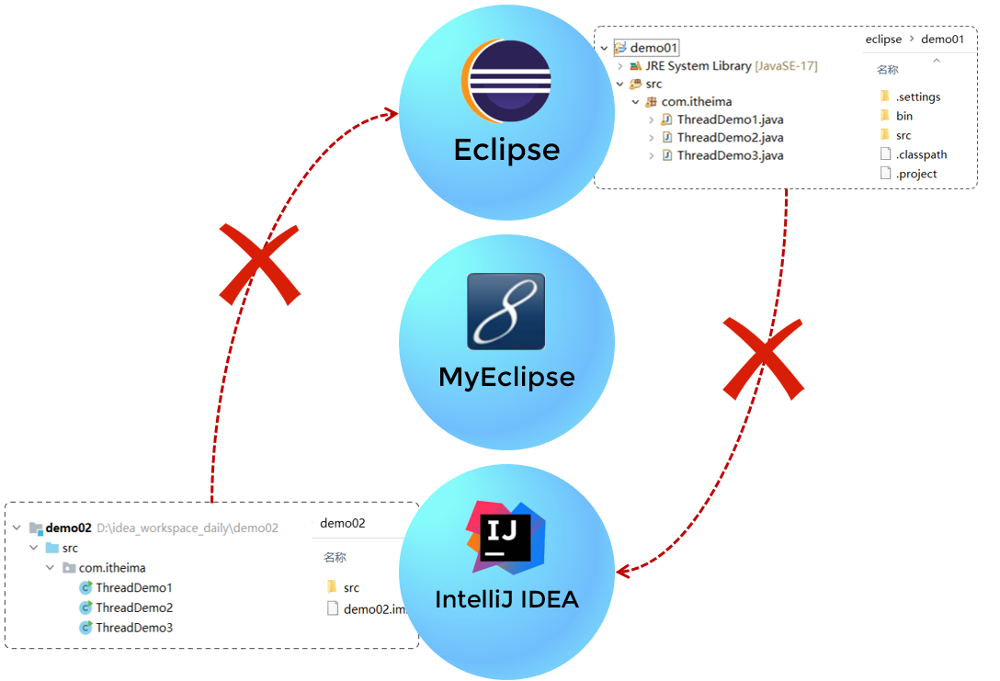

<strong>2). 使用Maven</strong>

而如果我们使用了Maven这一款项目构建工具，它给我们提供了一套标准的java项目目录。如下所示：

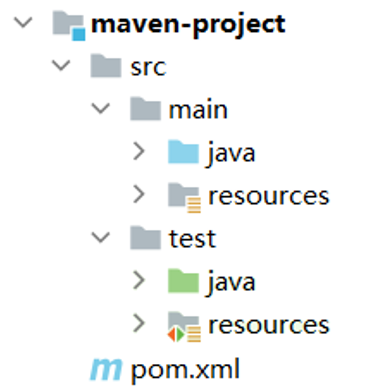

也就意味着，无论我们使用的是什么开发工具，只要是基于maven构建的java项目，最终的目录结构都是相同的，如图所示。 那这样呢，我们使用Eclipse、MyEclipse、IDEA创建的maven项目，就可以在各个开发工具直接直接导入使用了，更加方便、快捷。

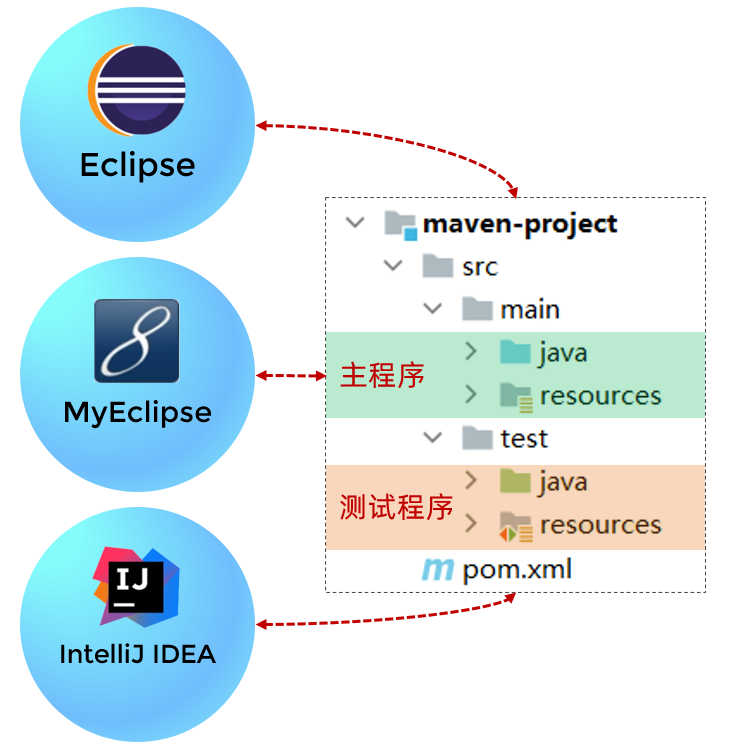

**配图目录转写：**

```text
maven-project/
├── pom.xml
├── src/
│   ├── main/
│   │   ├── java/          Java 业务源代码
│   │   └── resources/     主程序使用的配置、资源文件
│   └── test/
│       ├── java/          测试代码
│       └── resources/     测试使用的配置、资源文件
└── target/                构建后生成；存放编译结果、测试报告和包
```

> **补充：**目录属于约定，不是要求所有目录创建后都有内容。`resources` 不只存配置，也可以存程序需要读取的其他资源。`target` 是生成目录，不把自己的原始代码放在里面；`mvn clean` 默认会清理它。

而在上面的maven项目的目录结构中，main目录下存放的是项目的源代码，test目录下存放的是项目的测试代码。 而无论是在main还是在test下，都有两个目录，一个是java，用来存放源代码文件；另一个是resources，用来存放配置文件。

最后呢，一句话总结一下什么是Maven。 <strong>Maven就是一款管理和构建java项目的工具。</strong>

Maven的内容，我们进行了分层的设计和讲解，分为两个部分：Maven核心和Maven进阶。 那今天，我们先来讲解Maven核心部分的内容，在Web开发的最后，我们再来讲解Maven进阶部分的内容。


## 2 Maven概述


### 2.1 Maven介绍

Apache Maven是一个项目管理和构建工具，它基于项目对象模型(Project Object Model , 简称: POM)的概念，通过一小段描述信息来管理项目的构建、报告和文档。

官网：<a href="https://maven.apache.org/">https://maven.apache.org/</a>

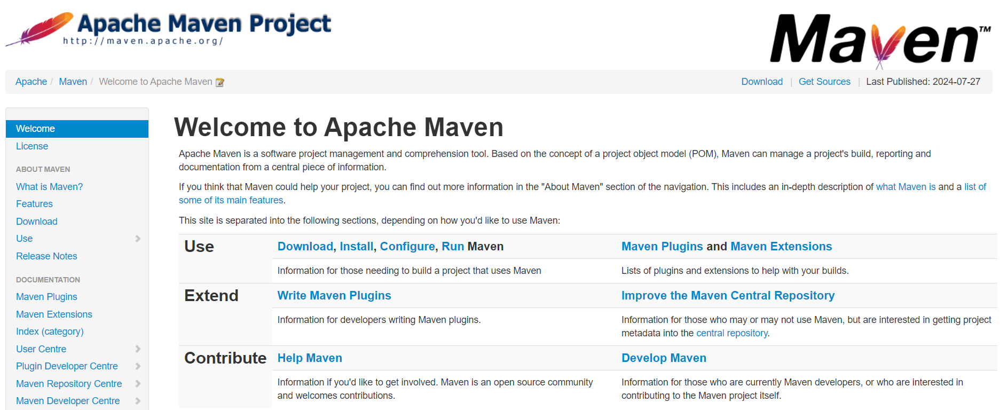

Maven的作用： 

1. 方便的依赖管理
2. 统一的项目结构
3. 标准的项目构建流程


### 2.2 Maven模型

- 项目对象模型 (Project Object Model)
- 依赖管理模型(Dependency)
- 构建生命周期/阶段(Build lifecycle &amp; phases)

1). 构建生命周期/阶段(Build lifecycle &amp; phases)

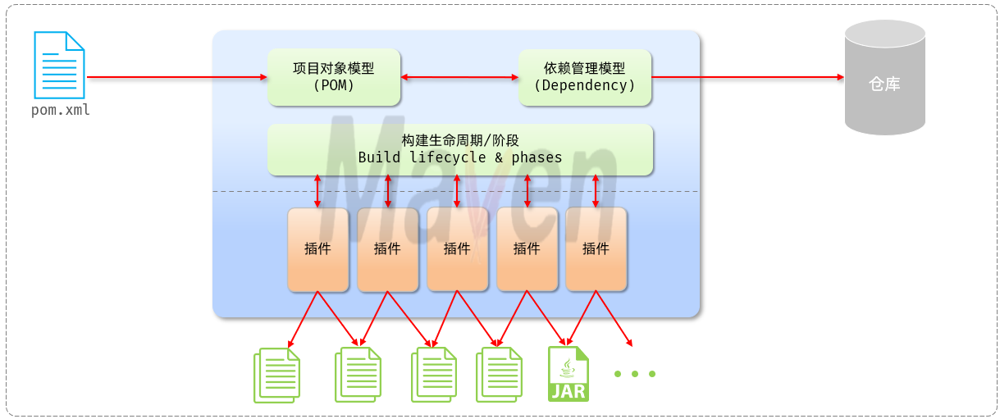

以上图中紫色框起来的部分，就是用来完成标准化构建流程 。当我们需要编译，Maven提供了一个编译插件供我们使用；当我们需要打包，Maven就提供了一个打包插件供我们使用等。 

2). 项目对象模型 (Project Object Model)

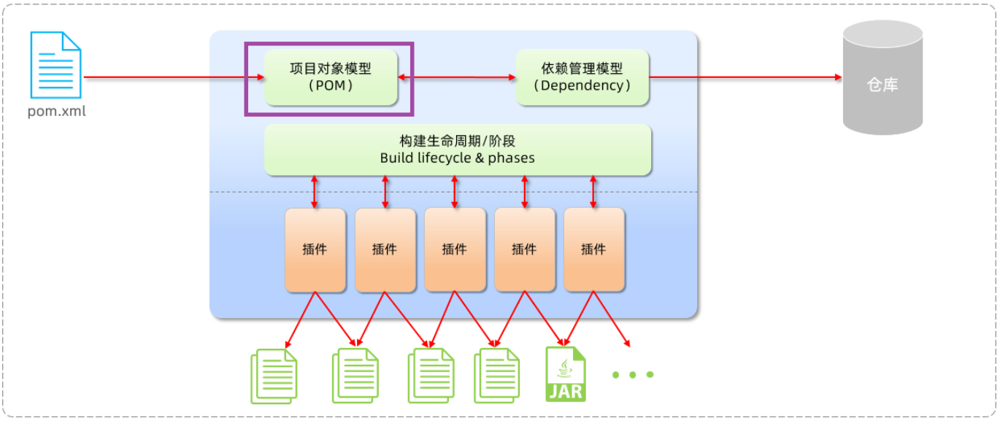

以上图中紫色框起来的部分属于项目对象模型，就是将我们自己的项目抽象成一个对象模型，有自己专属的坐标，如下图所示是一个Maven项目：

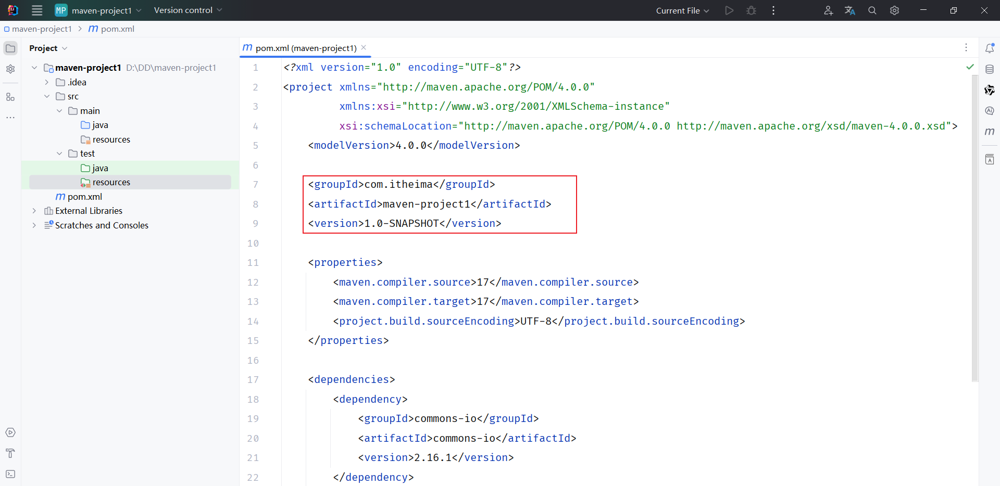

> 坐标，就是资源(jar包)的唯一标识，通过坐标可以定位到所需资源(jar包)位置。
> 
> 坐标的组成部分：
> 
> - groupId: 组织名
> - arfitactId: 模块名
> 
> > **勘误：**标签拼写是 `artifactId`，版本标签是小写的 `version`；XML 标签区分大小写。
> - Version: 版本号

3). 依赖管理模型(Dependency)

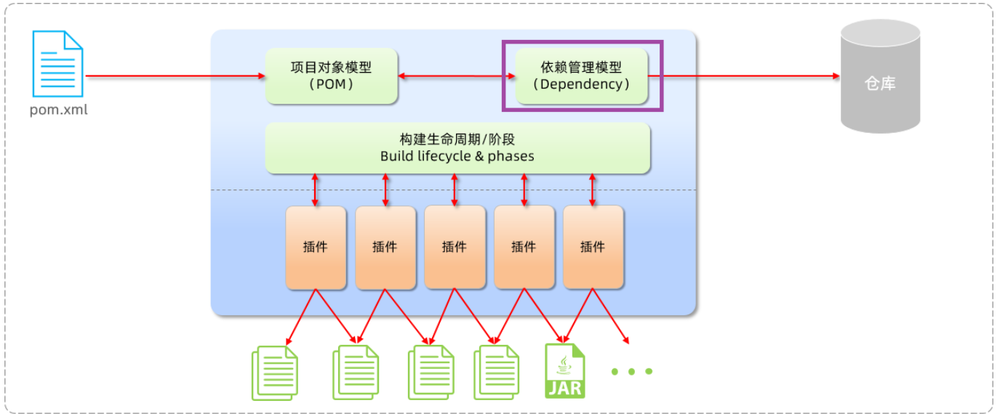

以上图中紫色框起来的部分属于依赖管理模型，是使用坐标来描述当前项目依赖哪些第三方jar包。

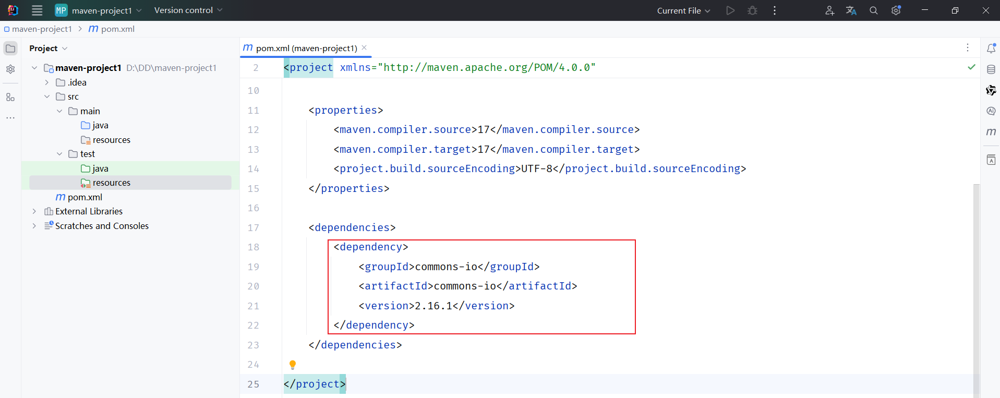

之前我们项目中需要jar包时，直接就把jar包复制到项目下的lib目录，而现在我们只需要在pom.xml中配置依赖的配置文件即可。 而这个依赖对应的jar包其实就在我们本地电脑上的maven仓库中。 

如下图，就是老师本地的maven仓库中的jar文件：

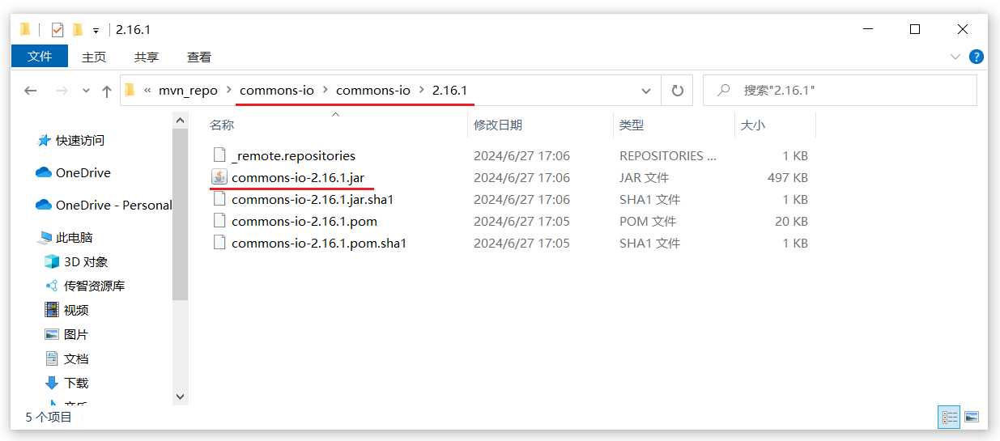


### 2.3 Maven仓库

仓库：用于存储资源，管理各种jar包

> <strong>仓库的本质</strong>就是一个目录(文件夹)，这个目录被用来存储开发中所有依赖(就是jar包)和插件

Maven仓库分为：

- 本地仓库：自己计算机上的一个目录(用来存储jar包)
- 中央仓库：由Maven团队维护的全球唯一的。仓库地址：https://repo1.maven.org/maven2/
- 远程仓库(私服)：一般由公司团队搭建的私有仓库

> **补充：**“远程仓库”是更宽泛的概念，中央仓库、公共镜像和公司私服都属于远程仓库。本地仓库还存放 POM、插件及解析元数据，不只有 JAR。默认本地路径为用户目录下的 `.m2/repository`，课程随后会改成自定义目录。

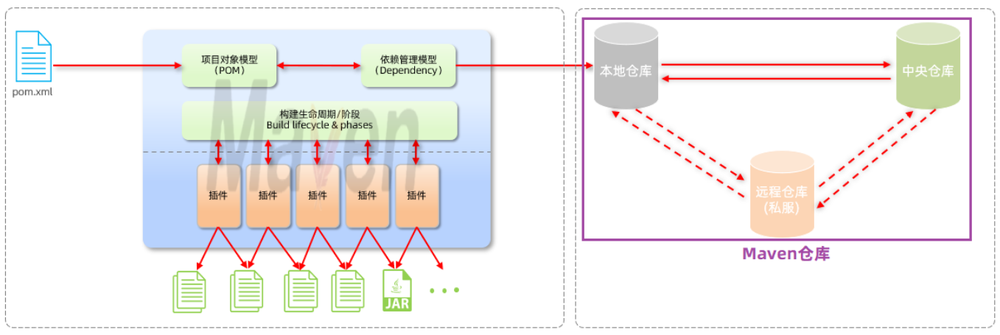

当项目中使用坐标引入对应依赖jar包后，

- 首先会查找本地仓库中是否有对应的jar包

    - 如果有，则在项目直接引用
    - 如果没有，则去中央仓库中下载对应的jar包到本地仓库
- 如果还可以搭建远程仓库(私服)，将来jar包的查找顺序则变为： 本地仓库 --&gt; 远程仓库--&gt; 中央仓库

> **补充：**这是便于入门理解的查找示意。实际访问哪个远程地址，取决于 `repositories`、`mirrors` 和更新策略。公司私服常会代理中央仓库；若为 `central` 配置了镜像，Maven 会改访问镜像，并非镜像失败后一定自动再试中央仓库。普通已缓存的发布版依赖通常复用本地文件，快照和元数据可能仍需检查更新。


### 2.4 Maven安装

认识了Maven后，我们就要开始使用Maven了，那么首先我们要进行Maven的下载与安装。


#### 2.4.1 下载

- 下载地址：https://maven.apache.org/download.cgi
- 在提供的资料中，已经提供了下载好的安装包。如下： 

> **补充：**本章沿用 Maven `3.9.4` 和 JDK `17` 的讲义环境，便于对照截图。Maven 本身需要 Java 运行环境，安装前应确认 `java -version` 和 `javac -version` 可用。安装历史版本可在 [Apache Maven 历史归档](https://archive.apache.org/dist/maven/maven-3/3.9.4/binaries/)查找；官方网站当前下载页的版本与讲义截图可能不同。

**讲义附件：**[apache-maven-3.9.4-bin.zip](https://heuqqdmbyk.feishu.cn/space/api/box/stream/download/all/TwZhbiJ4VowRsJxUVMbc8UzwnWh/)


#### 2.4.2 安装步骤

Maven安装配置步骤：

1. 解压安装
2. 配置仓库
3. 配置阿里云私服
4. 配置Maven环境变量

<strong>1). 解压 apache-maven-3.9.4-bin.zip（解压即安装）</strong>

建议解压到没有中文、特殊字符的路径下。如课程中解压到 <code>E:&#92;develop</code> 下。

解压缩后的目录结构如下：

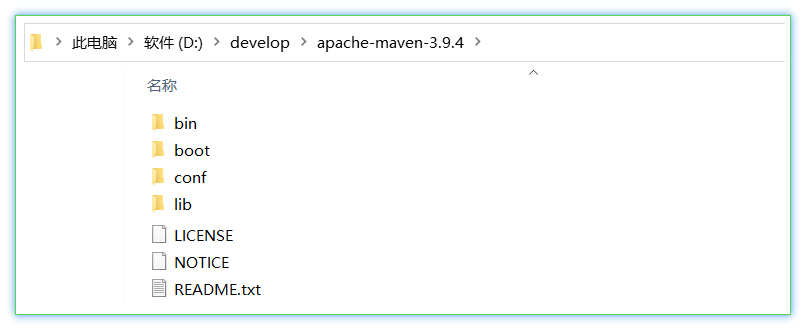

- bin目录 ： 存放的是可执行命令。（mvn 命令重点关注）
- conf目录 ：存放Maven的配置文件。（settings.xml配置文件后期需要修改）
- lib目录 ：存放Maven依赖的jar包。（Maven也是使用java开发的，所以它也依赖其他的jar包）

<strong>2). 配置本地仓库</strong>

1. 在自己计算机上新一个目录（本地仓库，用来存储jar包）

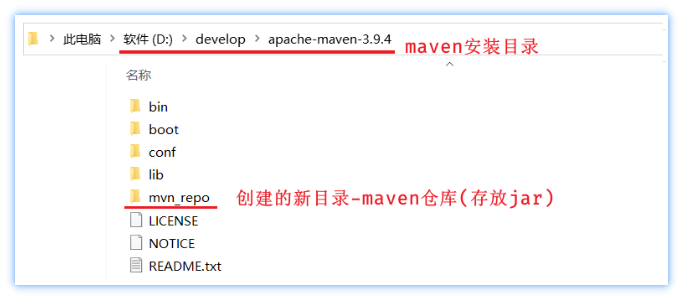

 

1. 进入到conf目录下修改<code>settings.xml</code>配置文件 

    1. 使用超级记事本软件，打开settings.xml文件，定位到53行
    2. 复制<code>&lt;localRepository&gt;</code>标签，粘贴到注释的外面（55行）
    3. 复制之前新建的用来存储jar包的路径，替换掉<code>&lt;localRepository&gt;</code>标签体内容 

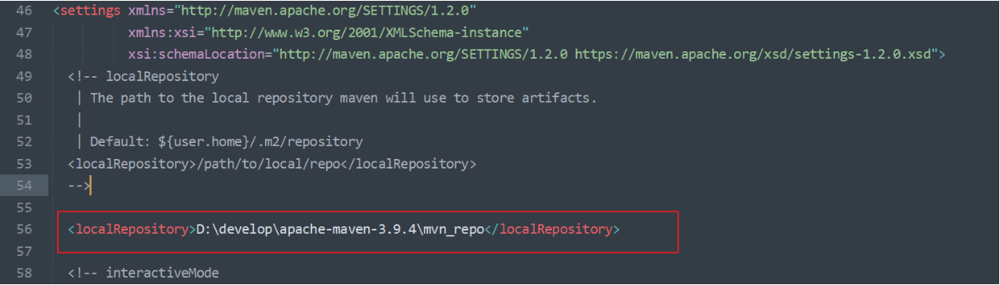

**配图配置转写：**讲义截图把仓库放在 Maven 安装目录下。按自己的实际磁盘路径填写，不能直接照搬老师的盘符。

```xml
<localRepository>D:/develop/apache-maven-3.9.4/mvn_repo</localRepository>
```

这行位于 `settings.xml` 的 `<settings> ... </settings>` 内、XML 注释之外。配置文件的行号会随版本变化，应搜索标签定位。

> **补充：**Maven 默认合并安装目录的 `conf/settings.xml` 和用户目录的 `.m2/settings.xml`，重叠配置以用户设置优先。项目的 `pom.xml` 描述项目；`settings.xml` 描述本机仓库、镜像等运行环境，两者作用不同。升级 Maven 时想继续复用缓存，也可把仓库放在安装目录之外，例如 `D:/develop/maven-repository`。

<strong>3). 配置阿里云私服</strong>

由于中央仓库在国外，所以下载jar包速度可能比较慢，而阿里公司提供了一个远程仓库，里面基本也都有开源项目的jar包。

进入到conf目录下修改settings.xml配置文件：

1. 使用超级记事本软件，打开settings.xml文件，定位到160行左右
2. 在<code>&lt;mirrors&gt;</code>标签下为其添加子标签<code>&lt;mirror&gt;</code>，内容如下：

````xml
<mirror>
    <id>alimaven</id>
    <name>aliyun maven</name>
    <url>http://maven.aliyun.com/nexus/content/groups/public/</url>
    <mirrorOf>central</mirrorOf>
</mirror>
````

> **勘误：**以上保留讲义的历史 HTTP 地址。实际配置建议使用 HTTPS 地址，避免新版本 Maven 的外部 HTTP 限制和旧入口兼容问题。`mirrorOf=central` 表示替代中央仓库，不能理解为“备用下载地址”。

**补充：可直接使用的镜像配置。**用下面这一项替换上面的同一镜像，不要重复添加两个相同 `id` 的条目。

```xml
<mirrors>
    <mirror>
        <id>aliyun-central</id>
        <name>Aliyun Maven Central Mirror</name>
        <url>https://maven.aliyun.com/repository/central</url>
        <mirrorOf>central</mirrorOf>
    </mirror>
</mirrors>
```

如果文件里已经有 `<mirrors>`，只添加内部的 `<mirror>`，不要再嵌套一层 `<mirrors>`。项目使用中央仓库以外的仓库时，本配置不会替代那些仓库。

注意配置的位置，在<code>&lt;mirrors&gt; ... &lt;/mirrors&gt;</code>中间添加配置。如下图所示：

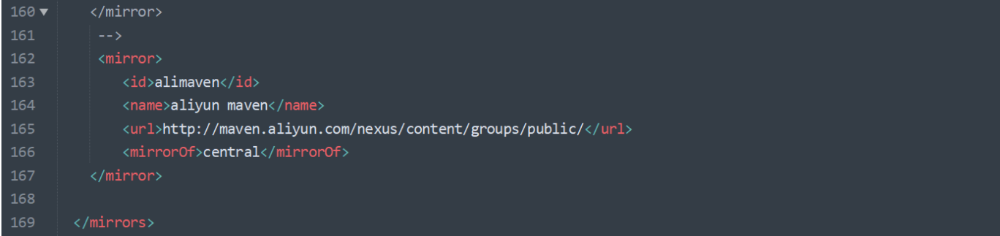

<strong>4).</strong><strong> 配置环境</strong><strong>变量</strong>

Maven环境变量的配置类似于JDK环境变量配置一样

1. 在系统变量处新建一个变量MAVEN&#95;HOME。 MAVEN&#95;HOME环境变量的值，设置为maven的解压安装目录

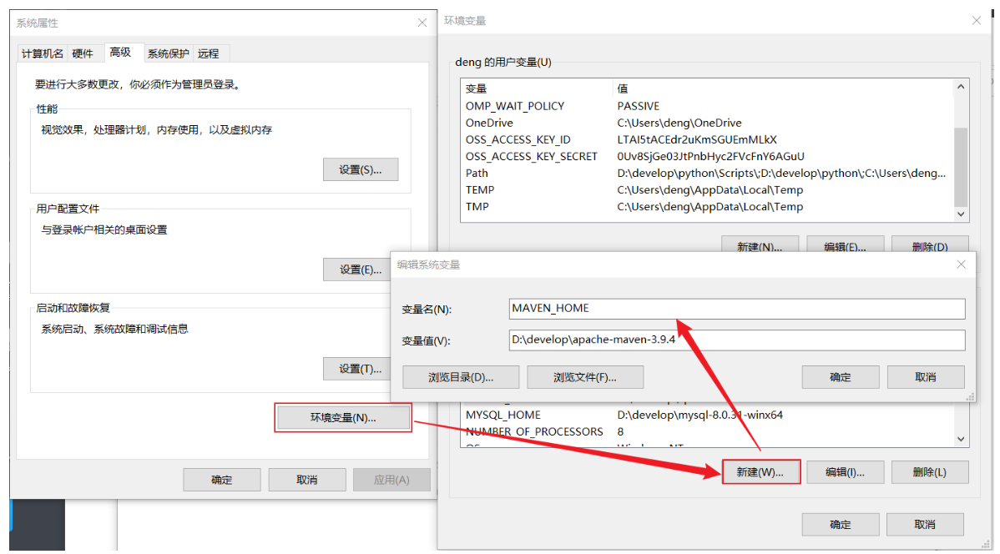

1. 在Path中进行配置。 PATH环境变量的值，设置为：%MAVEN&#95;HOME%&#92;bin

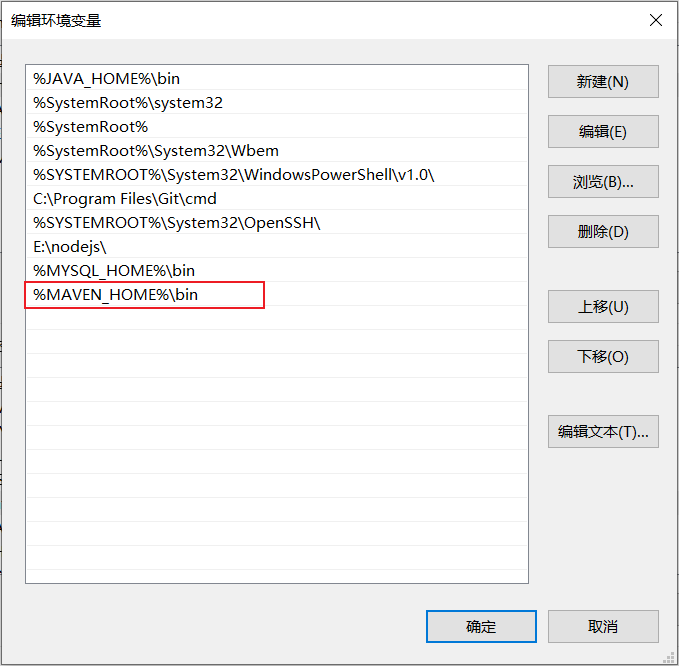

1. 打开DOS命令提示符进行验证，出现如图所示表示安装成功 。

命令为：<strong><code>mvn -v</code></strong>

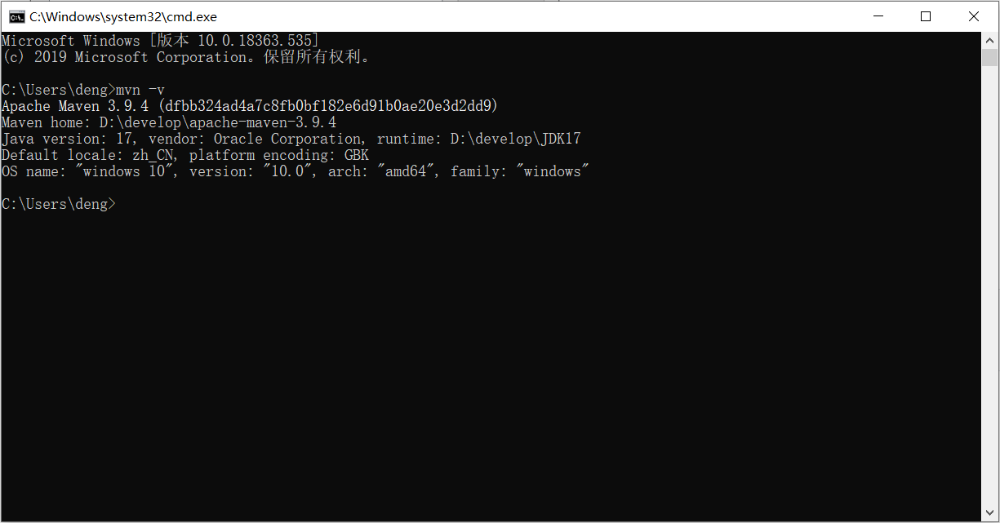

**操作转写：**重新打开终端，再执行：

```text
java -version
javac -version
mvn -v
```

检查输出中的 Maven version、Maven home、Java version 和 Java home。`MAVEN_HOME` 指向 Maven 根目录，`Path` 包含该目录的 `bin`；`JAVA_HOME` 应指向 JDK 根目录，不是 `bin`。Windows 环境变量界面里的 `%MAVEN_HOME%\bin` 是 Path 的值，不是要直接运行的命令。

> **补充：**在 PowerShell 中排查命令来源可用 `Get-Command java, javac, mvn`；在 CMD 中可用 `where java`、`where mvn`。环境变量刚修改后，已打开的终端或 IDEA 可能仍保留旧环境，需要重新打开。

<strong>5). 配置关联的JDK</strong><strong>版</strong><strong>本(</strong><strong>可选</strong><strong>)</strong>

进入到conf目录下修改settings.xml配置文件，在 <code>&lt;profiles&gt; &lt;/profiles&gt;</code>中增加如下配置:

````xml
<profile>
        <id>jdk-17</id>
        <activation>
                <activeByDefault>true</activeByDefault>
                <jdk>17</jdk>
        </activation>
        <properties>
                <maven.compiler.source>17</maven.compiler.source>
                <maven.compiler.target>17</maven.compiler.target>
                <maven.compiler.compilerVersion>17</maven.compiler.compilerVersion>
        </properties>
</profile>
````

> **勘误：**上面是 XML 配置，原讲义把代码语言标成了 SQL。配置中的 `source/target` 决定编译接受的语言级别和输出字节码版本，**不会下载 JDK，也不会把运行 Maven 的 JDK 切换到 17**。真正使用哪个 JDK，先看 `mvn -v`；IDEA 中还要检查 Project SDK、Maven Runner/Importer 的 JDK。
>
> **补充：**这段 profile 可选。对单个项目，更容易复现的做法是在 `pom.xml` 中写编译版本；在支持的 Compiler Plugin 中可使用 `maven.compiler.release=17`，同时约束语言级别、字节码和可用的 Java SE API。`maven.compiler.compilerVersion` 不能替代 JDK 安装或选择。后面的完整练习会给出固定插件版本的 POM。


## 3 IDEA集成Maven

我们要想在IDEA中使用Maven进行项目构建，就需要在IDEA中集成Maven，那么就需要在IDEA中配置与maven的关联。


### 3.1 创建Maven项目


#### 3.1.1 全局设置

1. 进入IDEA的欢迎页面

    选择 IDEA中 File  =&gt;  <code>close project</code> =&gt; <code>Customize</code> =&gt; <code>All settings</code>

    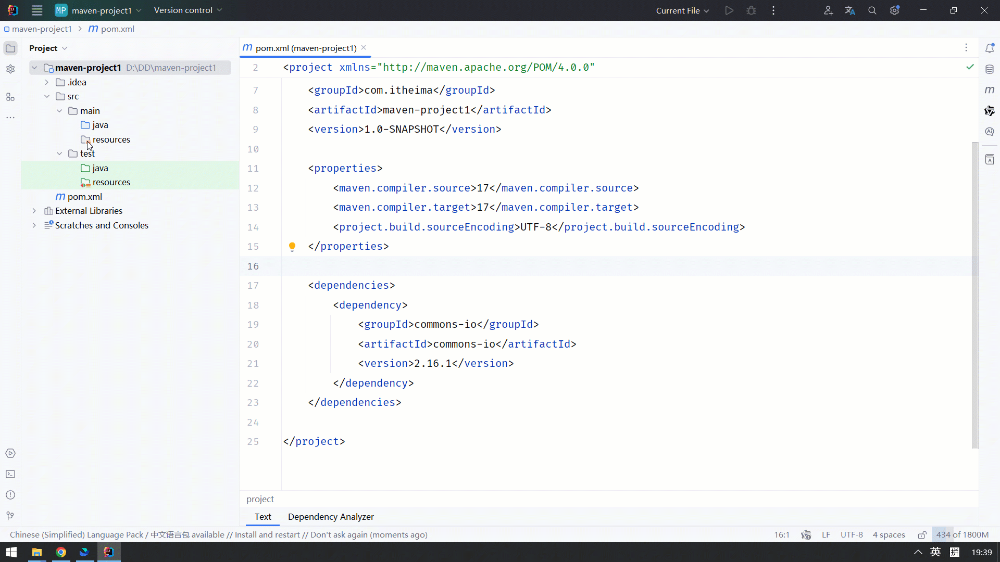

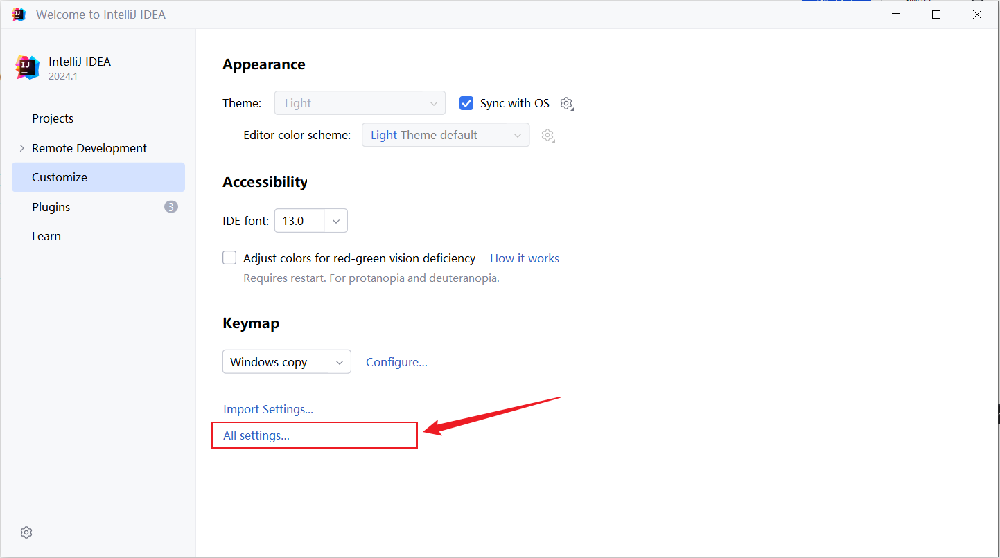

1. 打开 All settings , 选择 <code>Build,Execution,Deployment</code>  =&gt;  <code>Build Tools</code>  =&gt;  <code>Maven</code>

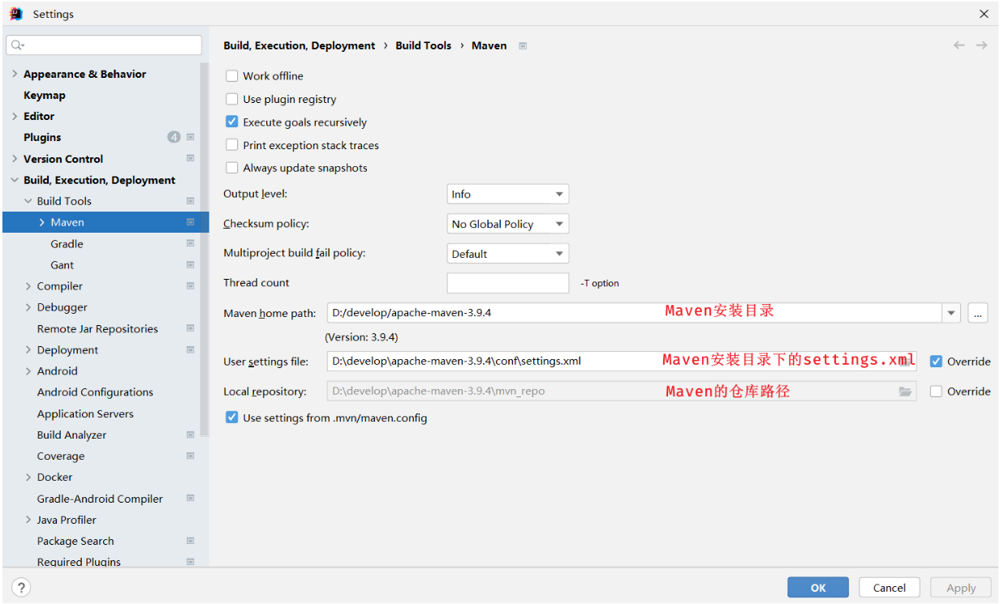

**配图设置项转写：**

| IDEA 字段 | 应填写的内容 | 核对目的 |
| --- | --- | --- |
| Maven home path | 解压后的 Maven 根目录，例如 `D:/develop/apache-maven-3.9.4` | 使用预期的 Maven 版本 |
| User settings file | 本章已修改的 `conf/settings.xml`，按界面勾选 Override | IDEA 与命令行使用一致的镜像和仓库配置 |
| Local repository | 与 `settings.xml` 中仓库路径一致 | 避免依赖分别下载到两个位置 |
| Work offline | 首次下载依赖时不要开启 | 允许从配置的远程仓库下载 |

> **补充：**新版 IDEA 的入口文字可能是“新项目设置 / Settings for New Projects”。全局设置主要影响以后新建的项目；已有项目还应进入自己的设置核对。编译器目标版本设成 17 后，也要让项目 POM 中的编译属性与之匹配，否则重新导入 Maven 时可能出现不一致。

1. 配置工程的编译版本为17

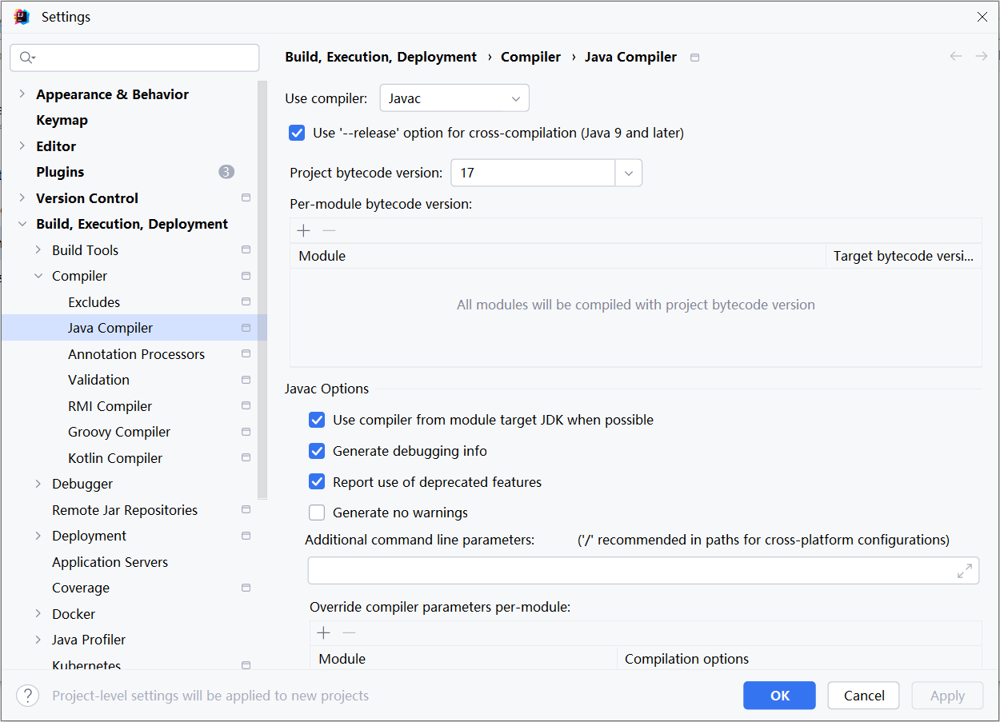

这里所设置的maven的环境信息，并未指定任何一个project，此时设置的信息就属于全局配置信息。 以后，我们再创建project，默认就是使用我们全局配置的信息。


#### 3.1.2 创建项目

1. 创建一个空项目，命名为 web-project01

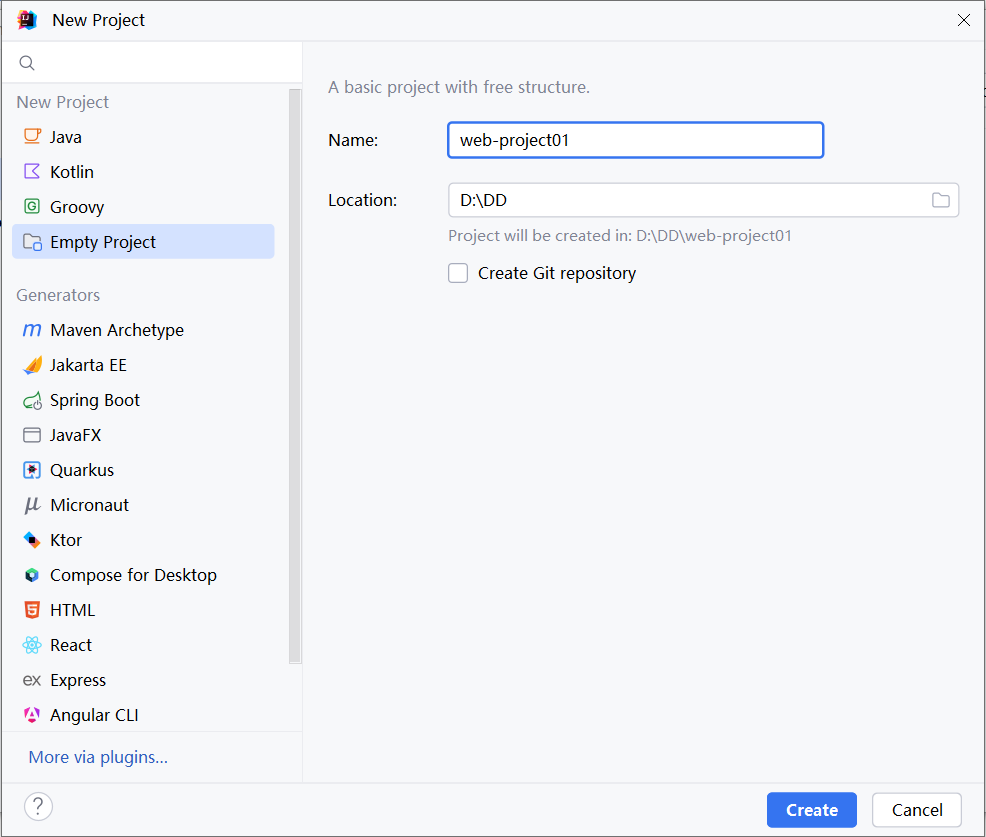

1. 创建好项目之后，进入项目中，要设置JDK的版本号。选择小齿轮，选择 <strong><code>Project Structure</code></strong>

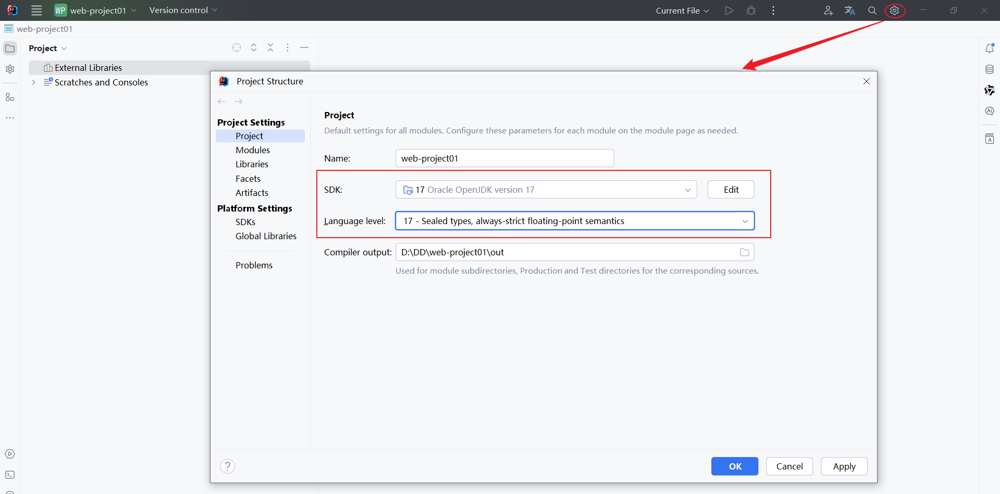

1. 创建模块，选择Java语言，选择Maven。 填写模块的基本信息

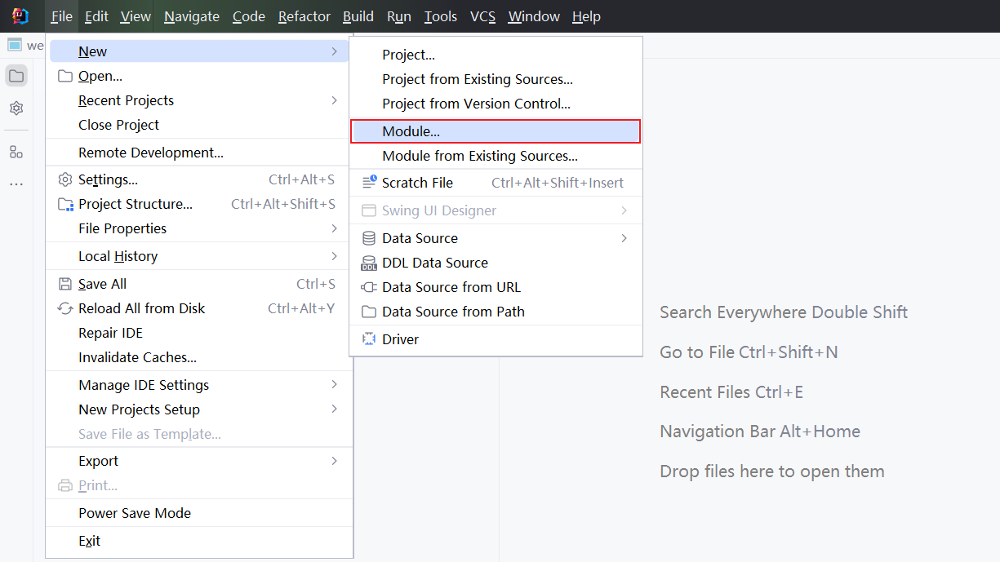

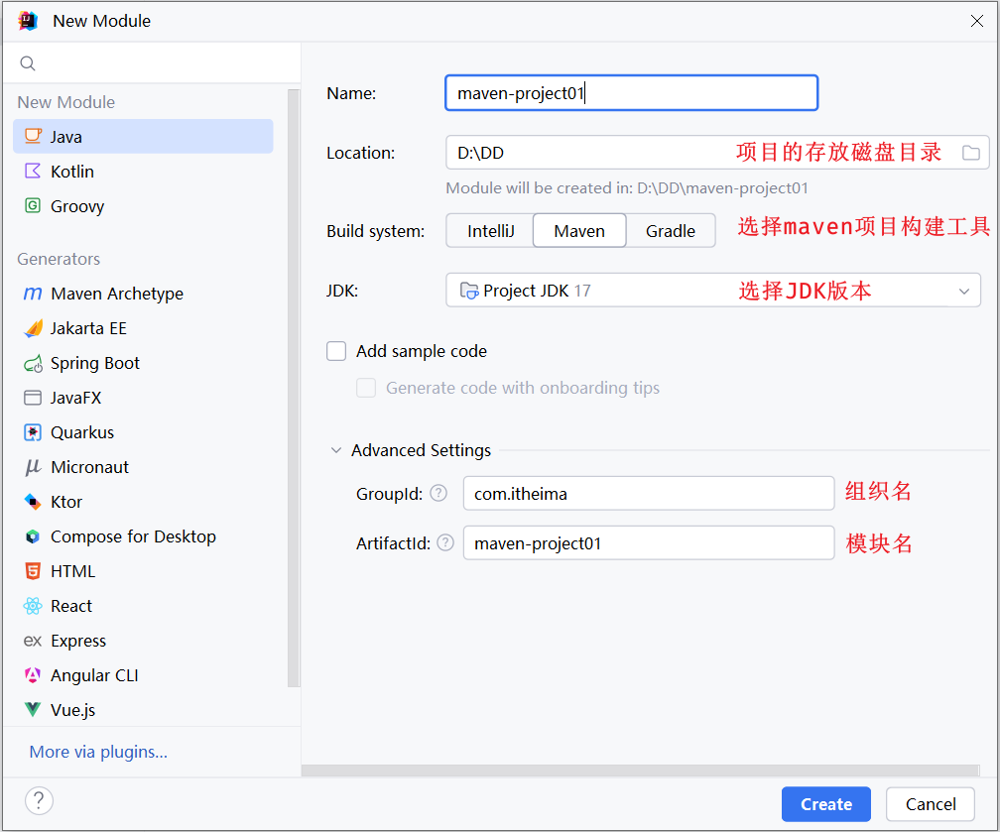

**配图创建参数转写：**外层 Empty Project 名为 `web-project01`；在其中新建 Java 模块，构建系统选择 Maven，模块名 `maven-project01`，JDK 选择已安装的 17，GroupId 为 `com.itheima`，ArtifactId 为 `maven-project01`。

> **补充：**外层空项目只是 IDEA 的组织方式，并不自动成为 Maven 父工程。在哪个目录执行 Maven，要看哪个目录有本次要构建的 `pom.xml`。

1. 在maven项目中，创建HelloWorld类，并运行

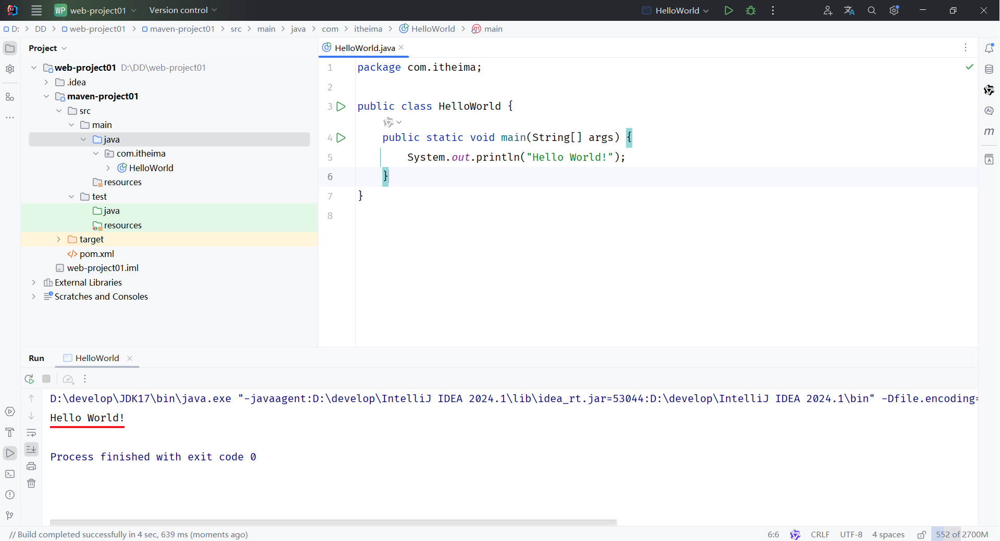

**补充：最小 HelloWorld 源文件。**在 `src/main/java/com/itheima/HelloWorld.java` 中写入以下内容，点击 `main` 旁边的运行按钮即可观察输出。

```java
package com.itheima;

public class HelloWorld {
    public static void main(String[] args) {
        System.out.println("Hello World");
    }
}
```

> <strong>Maven项目的目录结构:</strong>
> 
> ````text
> maven-project01
>         |---  src  (源代码目录和测试代码目录)
>                |---  main (源代码目录)
>                         |--- java (源代码java文件目录)
>                         |--- resources (源代码配置文件目录)
>               |---  test (测试代码目录)
>                         |--- java (测试代码java目录)
>                         |--- resources (测试代码配置文件目录)
>         |--- target (编译、打包生成文件存放目录)
> ````


#### 3.1.3 pom文件详解

POM (Project Object Model) ：指的是项目对象模型，用来描述当前的maven项目。

- 使用pom.xml文件来描述当前项目。 pom.xml文件如下：

````xml
<?xml version="1.0" encoding="UTF-8"?>
<project xmlns="http://maven.apache.org/POM/4.0.0"
         xmlns:xsi="http://www.w3.org/2001/XMLSchema-instance"
         xsi:schemaLocation="http://maven.apache.org/POM/4.0.0 http://maven.apache.org/xsd/maven-4.0.0.xsd">
    <!-- POM模型版本 -->
    <modelVersion>4.0.0</modelVersion>

    <!-- 当前项目坐标 -->
    <groupId>com.itheima</groupId>
    <artifactId>maven-project01</artifactId>
    <version>1.0-SNAPSHOT</version>
    
    <!-- 项目的JDK版本及编码 -->
    <properties>
        <maven.compiler.source>17</maven.compiler.source>
        <maven.compiler.target>17</maven.compiler.target>
        <project.build.sourceEncoding>UTF-8</project.build.sourceEncoding>
    </properties>

</project>
````

<strong>pom文件详解：</strong>

- <code>&lt;project&gt;</code><code> </code>：pom文件的根标签，表示当前maven项目
- <code>&lt;modelVersion&gt;</code>：声明项目描述遵循哪一个POM模型版本

    - 虽然模型本身的版本很少改变，但它仍然是必不可少的。目前POM模型版本是4.0.0
- 坐标 ：

    - <code>&lt;groupId&gt;</code> <code>&lt;artifactId&gt;</code> <code>&lt;version&gt;</code>
    - 定位项目在本地仓库中的位置，由以上三个标签组成一个坐标
- <code>&lt;maven.compiler.source&gt;</code> ：编译JDK的版本
- <code>&lt;maven.compiler.target&gt;</code> ：运行JDK的版本
- <code>&lt;project.build.sourceEncoding&gt;</code> : 设置项目的字符集

> **勘误：**`maven.compiler.source` 不是选择“编译器安装位置”，`maven.compiler.target` 也不是切换运行时 JDK，而是设置语言级别和生成的 class 版本。目标字节码为 17 的程序通常需要 Java 17 或更高版本运行。`project.build.sourceEncoding` 声明源码编码，不能自动修复原本就保存成其他编码的文件。
>
> **补充：**`modelVersion=4.0.0` 是这里使用的 POM 模型版本，既不是 Maven 工具版本，也不是自己的项目版本。本章普通 Java 项目省略 `packaging` 时默认按 `jar` 打包。


### 3.2 Maven坐标

什么是坐标？

- Maven中的坐标是<strong>资源</strong><strong>的唯一标识</strong> , 通过该坐标可以唯一定位资源位置
- 使用坐标来定义项目或引入项目中需要的依赖

Maven坐标主要组成：

- groupId：定义当前Maven项目隶属组织名称（通常是域名反写，例如：com.itheima）
- artifactId：定义当前Maven项目名称（通常是模块名称，例如 order-service、goods-service）
- version：定义当前项目版本号

    - SNAPSHOT: 功能不稳定、尚处于开发中的版本，即快照版本
    - RELEASE: 功能趋于稳定、当前更新停止，可以用于发行的版本

    > **补充：**这里的 RELEASE 是发布版本的概念，并不要求所有版本号都以 `-RELEASE` 结尾。`1.0.0` 就是常见发布版号，`1.0-SNAPSHOT` 表示开发中的快照。发布一个版本不意味着整个项目以后不再更新，后续仍可以发布新版本；同一发布版坐标通常应保持内容不变。

如下图就是使用坐标表示一个项目：

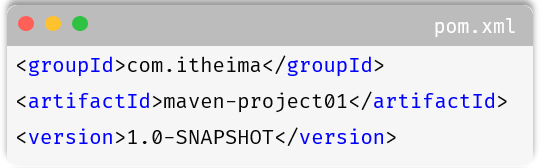

> <strong>注意：</strong>
> 
> - 上面所说的资源可以是插件、依赖、当前项目。
> - 我们的项目如果被其他的项目依赖时，也是需要坐标来引入的。


### 3.3 导入Maven项目

在IDEA中导入Maven项目，有两种方式。

- 方式一：<code>File</code> -&gt; <code>Project Structure</code> -&gt; <code>Modules</code> -&gt; <code>Import Module</code> -&gt; <code>选择maven项目的pom.xml</code>。

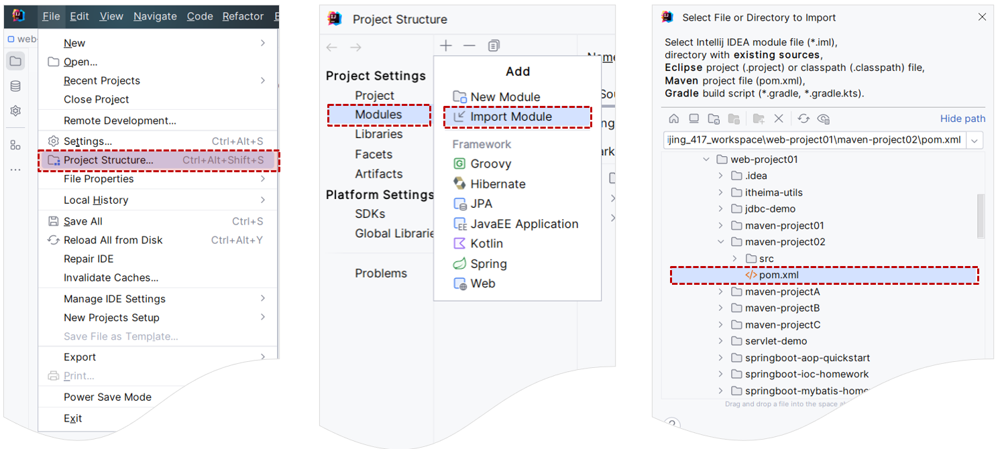

- 方式二：<code>Maven面板</code> -&gt; <code>+（Add Maven Projects）</code> -&gt; <code>选择maven项目的pom.xml</code>。

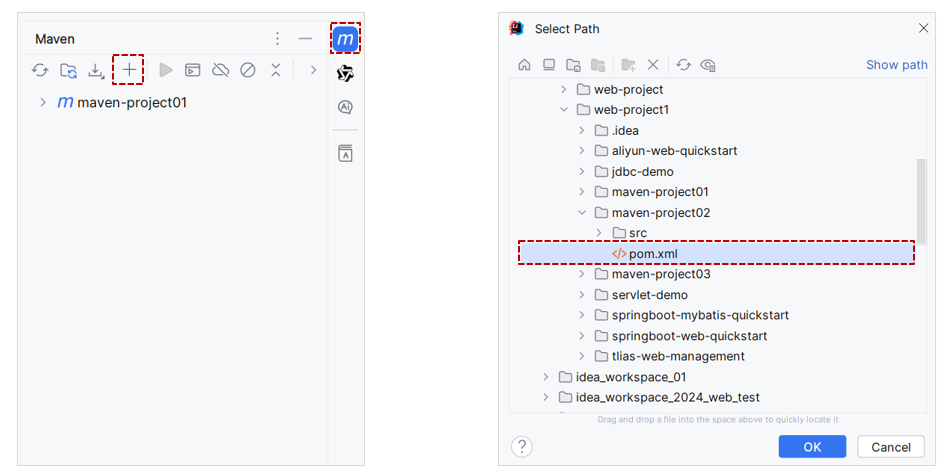


## 4 依赖管理


### 4.1 依赖配置


#### 4.1.1 基本配置

依赖：指当前项目运行所需要的jar包。一个项目中可以引入多个依赖：

例如：在当前工程中，我们需要用到logback来记录日志，此时就可以在maven工程的pom.xml文件中，引入logback的依赖。具体步骤如下：

> **勘误：**这句话提到了 Logback，但下面的完整 XML 实际演示 `org.springframework:spring-context:6.1.4`。先按 Spring Context 的坐标理解依赖配置；接下来的查找动图才使用 `logback-classic`。

1. 在pom.xml中编写<code>&lt;dependencies&gt;</code>标签
2. 在<code>&lt;dependencies&gt;</code>标签中使用<code>&lt;dependency&gt;</code>引入坐标
3. 定义坐标的 <code>groupId</code>、<code>artifactId</code>、<code>version</code>

````xml
<dependencies>
    <!-- 依赖 : spring-context -->
    <dependency>
        <groupId>org.springframework</groupId>
        <artifactId>spring-context</artifactId>
        <version>6.1.4</version>
    </dependency>
</dependencies>
````

1. 点击刷新按钮，引入最新加入的坐标

刷新依赖：保证每一次引入新的依赖，或者修改现有的依赖配置，都可以加入最新的坐标

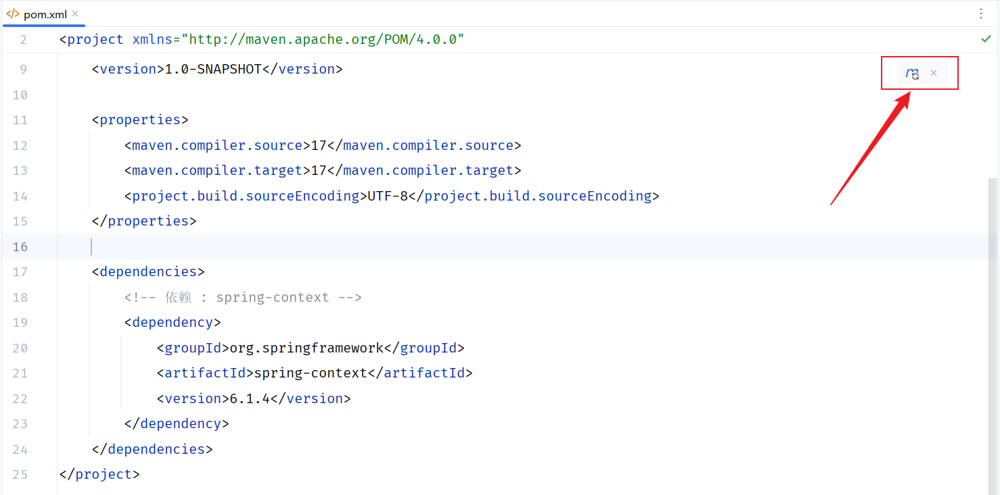

> <strong>注意事项：</strong>
> 
> 1. 如果引入的依赖，在本地仓库中不存在，将会连接远程仓库 / 中央仓库，然后下载依赖（这个过程会比较耗时，耐心等待）
> 2. 如果不知道依赖的坐标信息，可以到mvn的中央仓库（https://mvnrepository.com/）中搜索
> 
> > **勘误：**[MVN Repository](https://mvnrepository.com/)是常用的坐标检索网站，不是 Maven Central 仓库服务本身。复制时核对组织名、模块名和版本，把单个 `dependency` 放进已有的 `dependencies`，不要把网站页面地址当成仓库下载地址。


#### 4.1.2 查找依赖

1. 利用中央仓库搜索的依赖坐标，以常见的logback-classic为例。

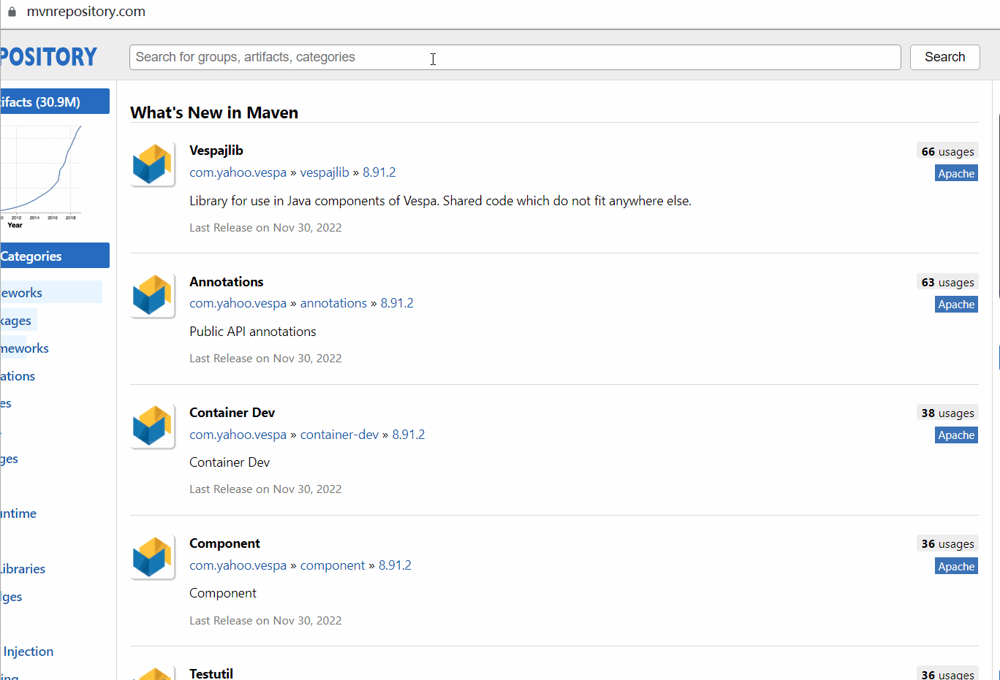

1. 利用IDEA工具搜索依赖，以常见的logback-classic为例。

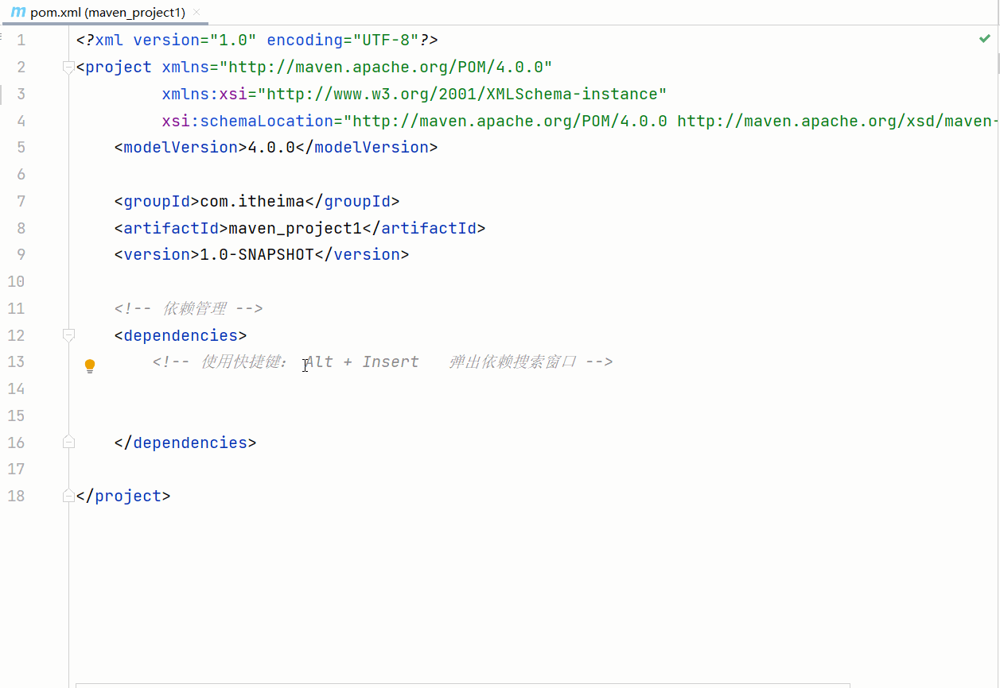

1. 熟练上手maven后，快速导入依赖，以常见的logback-classic为例。

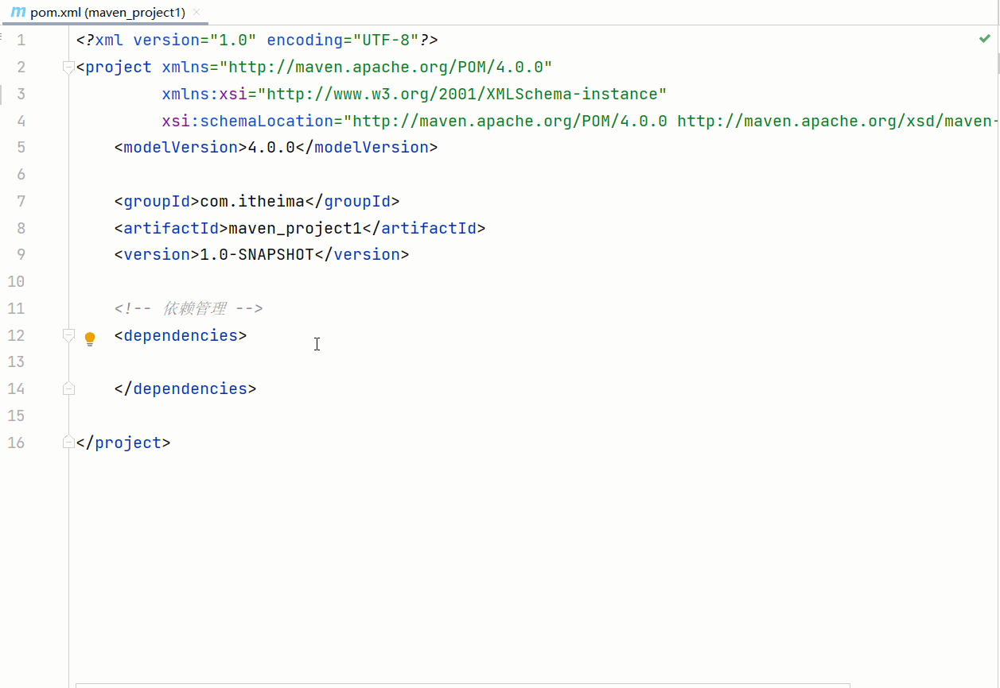

**三张动图的操作转写：**

1. 在坐标检索网站搜索 `logback-classic`，进入对应组件，选择讲义需要的版本，复制 Maven 格式的 XML。
2. 在 IDEA 的 POM 编辑界面使用依赖搜索/补全功能，核对 `groupId`、`artifactId`、`version` 后插入；不同版本 IDEA 的入口和索引状态可能不同。
3. 熟悉坐标后可直接手写 `dependency`。保存并 Reload Maven Project，等待下载完成，在 Maven 面板或 External Libraries 中检查结果。

> **补充：**版本号应根据项目要求选择，并非列表里排在最前面的版本一定适合当前 JDK。补全没有结果时仍可按官方文档中的坐标手动填写。


#### 4.1.3 依赖传递

我们上面在pom.xml中配置了一项依赖，就是spring-context，但是我们通过右侧的maven面板可以看到，其实引入进来的依赖，并不是这一项，有非常多的依赖，都引入进来了。我们可以看到如下图所示：

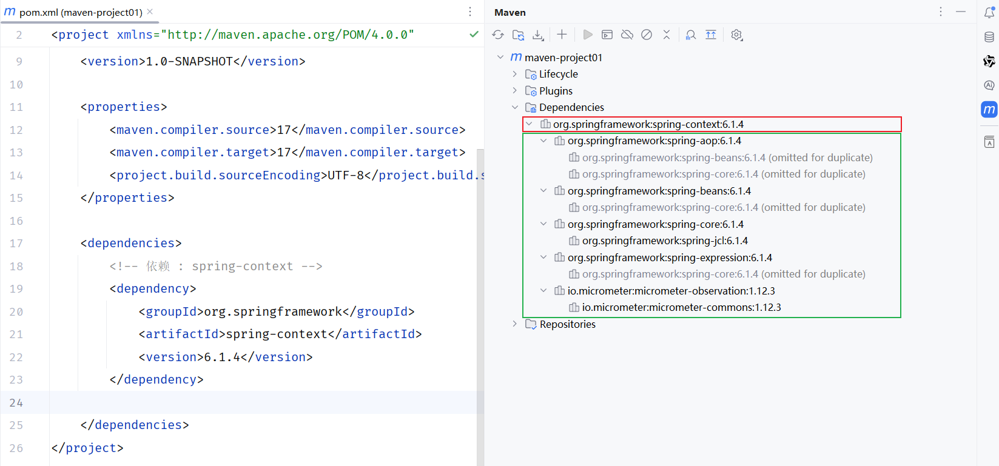

为什么会出现这样的现象呢? 那这里呢，就涉及到maven中非常重要的一个特性，那就是Maven中的<strong>依赖传递</strong>。

所谓maven的依赖传递，指的就是如果在maven项目中，A 依赖了B，B依赖了C，C依赖了D，那么在A项目中，也会有C、D依赖，因为依赖会传递。

> **补充：**依赖传递还受 `scope`、可选依赖和排除规则影响，不是所有依赖都无条件向下传递。对同一组件出现的多个版本，Maven 通常按“路径更近优先；深度相同时先声明者优先”调解。可在项目 POM 所在目录运行 `mvn dependency:tree` 查看实际使用的依赖树；选中了一个版本，并不保证它与所有调用方兼容。

那如果，传递下来的依赖，在项目开发中，我们确实不需要，此时，我们可以通过Maven中的排除依赖功能，来将这个依赖排除掉。


#### 4.1.4 排除依赖

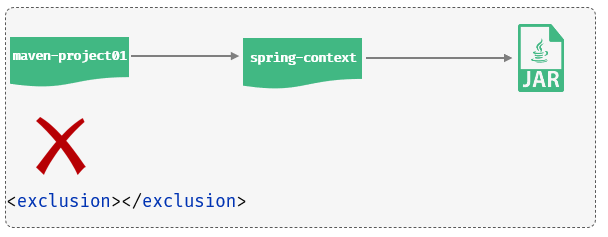

-  排除依赖：指主动断开依赖的资源，被排除的资源无需指定版本。
- 配置形式如下：

````xml
<dependency>
    <groupId>org.springframework</groupId>
    <artifactId>spring-context</artifactId>
    <version>6.1.4</version>

    <!--排除依赖, 主动断开依赖的资源-->
    <exclusions>
        <exclusion>
            <groupId>io.micrometer</groupId>
            <artifactId>micrometer-observation</artifactId>
        </exclusion>
    </exclusions>
</dependency>
````

> **补充：**这里演示的是在 `spring-context` 这条依赖路径上排除 `micrometer-observation`，不写版本号。如果同一组件还通过别的直接依赖进入项目，它仍可能存在；需要用依赖树核对。业务实际需要的间接依赖不能随意删除，否则可能出现 `ClassNotFoundException`、`NoClassDefFoundError` 等运行错误。

<strong>依赖排除示例：</strong>

1. 默认通过maven的依赖传递，传递下来了 <code>micrometer-observation</code> 的依赖。

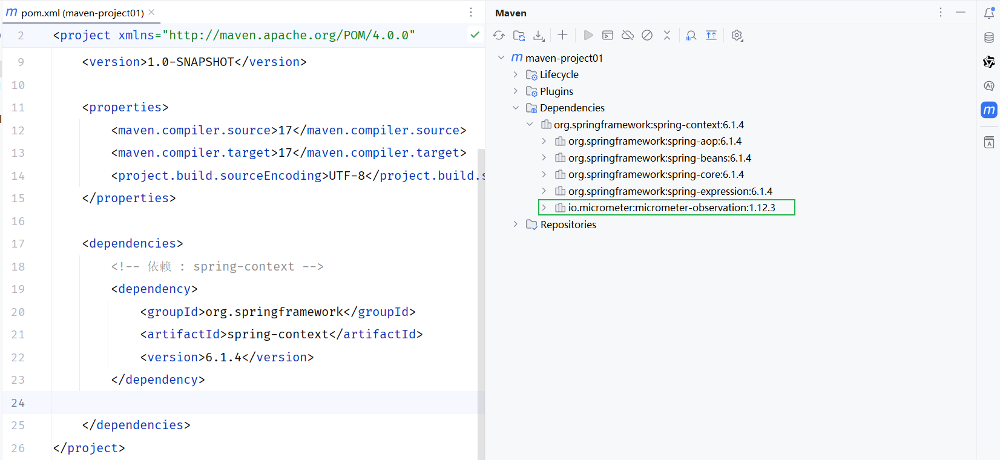

1. 加入排除依赖的配置之后，该依赖就被排除掉了。

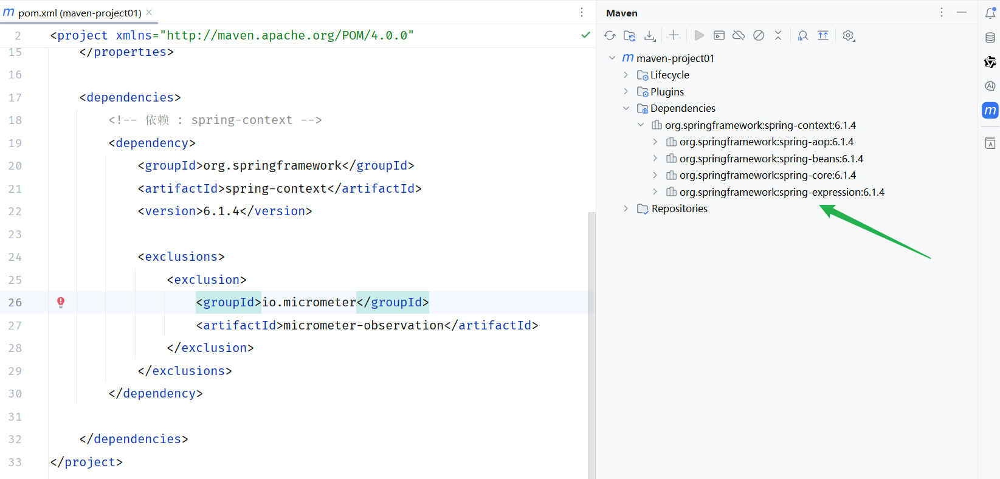


### 4.2 生命周期


#### 4.2.1 介绍

Maven的生命周期就是为了对所有的构建过程进行抽象和统一。 描述了一次项目构建，经历哪些阶段。

在Maven出现之前，项目构建的生命周期就已经存在，软件开发人员每天都在对项目进行清理，编译，测试及部署。虽然大家都在不停地做构建工作，但公司和公司间、项目和项目间，往往使用不同的方式做类似的工作。

Maven从大量项目和构建工具中学习和反思，然后总结了一套高度完美的，易扩展的项目构建生命周期。这个生命周期包含了项目的清理，初始化，编译，测试，打包，集成测试，验证，部署和站点生成等几乎所有构建步骤。

Maven对项目构建的生命周期划分为3套（相互独立）：

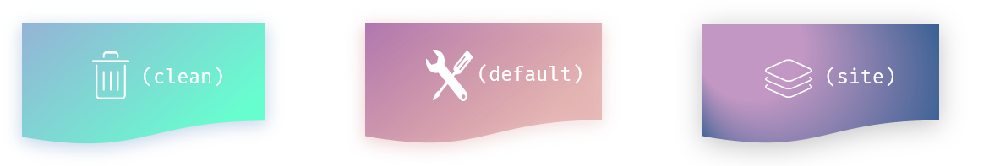

- clean：清理工作。
- default：核心工作。如：编译、测试、打包、安装、部署等。
- site：生成报告、发布站点等。

三套生命周期又包含哪些具体的阶段呢, 我们来看下面这幅图:

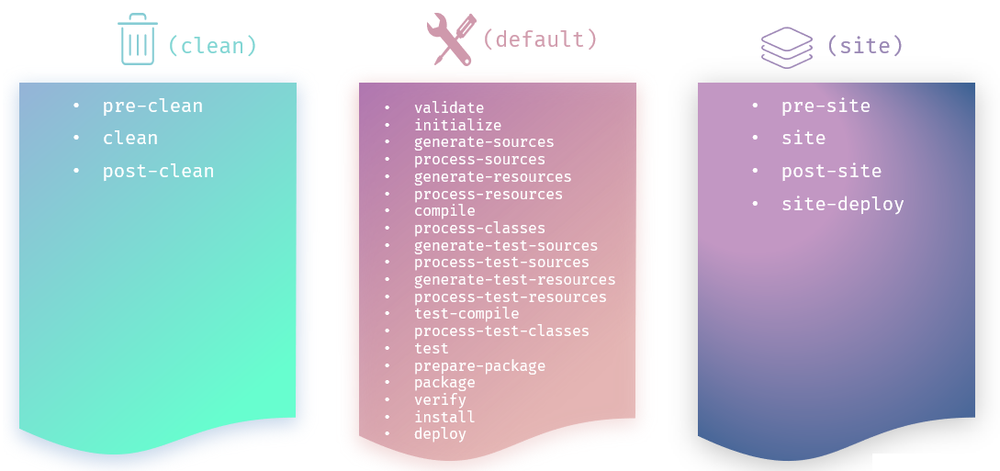

**配图阶段转写与补全：**下面分别列出三套生命周期，顺序只在各自内部成立。讲义图的 default 列省略了集成测试相关阶段，这里一并补齐。

```text
clean:
pre-clean → clean → post-clean

default:
validate → initialize
→ generate-sources → process-sources
→ generate-resources → process-resources
→ compile → process-classes
→ generate-test-sources → process-test-sources
→ generate-test-resources → process-test-resources
→ test-compile → process-test-classes → test
→ prepare-package → package
→ pre-integration-test → integration-test → post-integration-test
→ verify → install → deploy

site:
pre-site → site → post-site → site-deploy
```

> **补充：**`compile`、`test`、`package` 是阶段；例如 `compiler:compile`、`surefire:test` 是插件目标。Maven 进入阶段后，执行绑定在该阶段的插件目标；并非每个阶段都一定有独立任务。

每套生命周期包含一些阶段（phase），阶段是有顺序的，后面的阶段依赖于前面的阶段。

我们看到这三套生命周期，里面有很多很多的阶段，这么多生命周期阶段，其实我们常用的并不多，主要关注以下几个：

- clean：移除上一次构建生成的文件
- compile：编译项目源代码
- test：使用合适的单元测试框架运行测试(junit)
- package：将编译后的文件打包，如：jar、war等
- install：安装项目到本地仓库

Maven的生命周期是抽象的，这意味着生命周期本身不做任何实际工作。<strong>在Maven的设计中，实际任务（如源代码编译）都交由</strong><strong>插件</strong><strong>来完成。</strong>

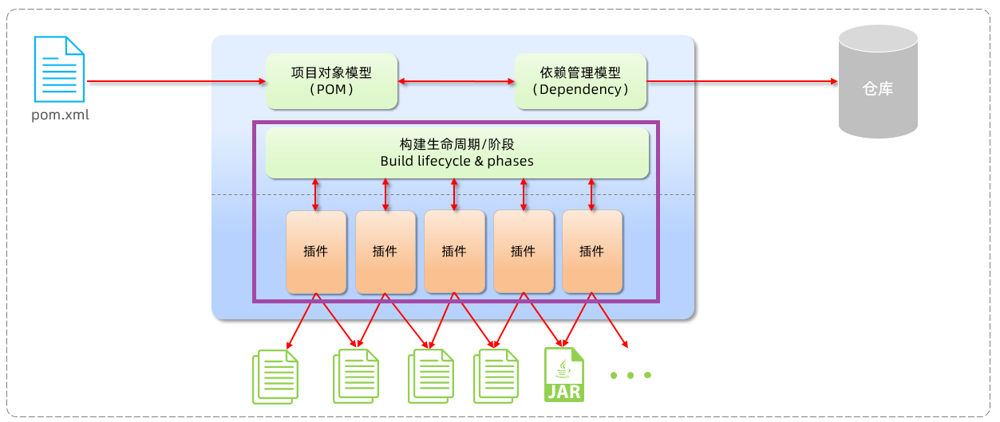

IDEA工具为了方便程序员使用maven生命周期，在右侧的maven工具栏中，已给出快速访问通道。

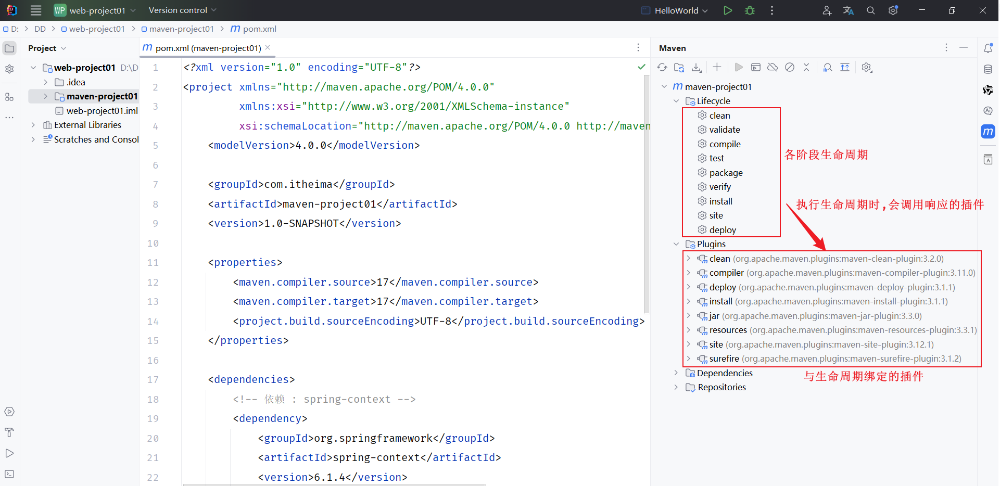

- 生命周期的顺序是：<code>clean</code> --&gt; <code>validate</code> --&gt; <code>compile</code> --&gt; <code>test</code> --&gt; <code>package</code> --&gt; <code>verify</code> --&gt; <code>install</code> --&gt; <code>site</code> --&gt; <code>deploy</code>

> **勘误：**以上把三套生命周期混成了一条链，不能按这条链推断执行顺序。正确规则是：指定某一阶段，会运行**该阶段所属生命周期中从开始到它为止**的阶段。`package` 不会自动执行 `clean`，`install` 不会自动执行 `site`，`deploy` 也不会自动把网站发布出去。
- 我们需要关注的就是：<code>clean</code> --&gt;  <code>compile</code> --&gt; <code>test</code> --&gt; <code>package</code>  --&gt; <code>install</code>

> <strong>说明：</strong>在同一套生命周期中，我们在执行后面的生命周期时，前面的生命周期都会执行。

> <strong>思考：</strong>当运行package生命周期时，clean、compile生命周期会不会运行？
> 
>     clean不会运行，compile会运行。  因为compile与package属于同一套生命周期，而clean与package不属于同一套生命周期。


#### 4.2.2 执行

在日常开发中，当我们要执行指定的生命周期时，有两种执行方式：

1. 在idea工具右侧的maven工具栏中，选择对应的生命周期，双击执行
2. 在DOS命令行中，通过maven命令执行

<strong>方式一：在idea中执行生命周期</strong>

- 选择对应的生命周期，双击执行

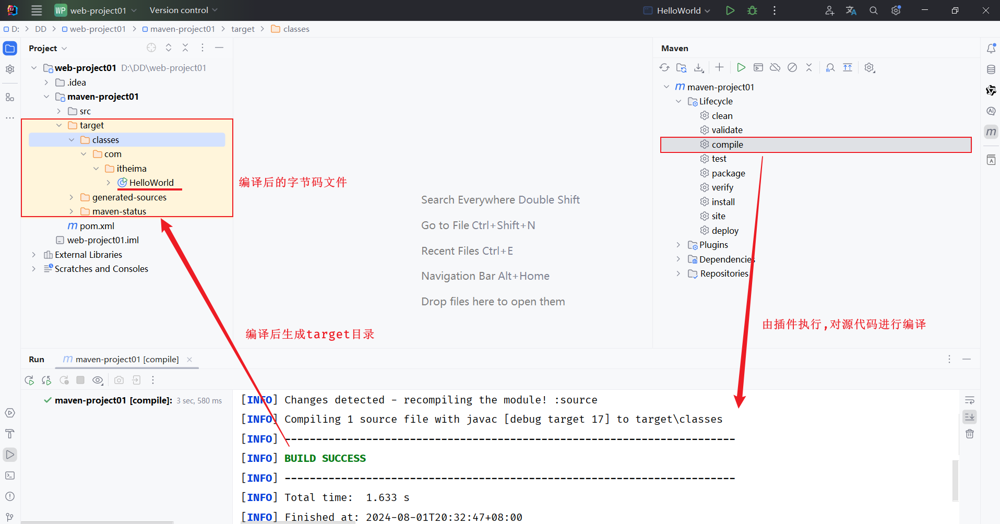

其他的生命周期都是类似的道理，双击运行即可。

<strong>方式二：在命令行中执行生命周期</strong>

1. 打开maven项目对应的磁盘目录

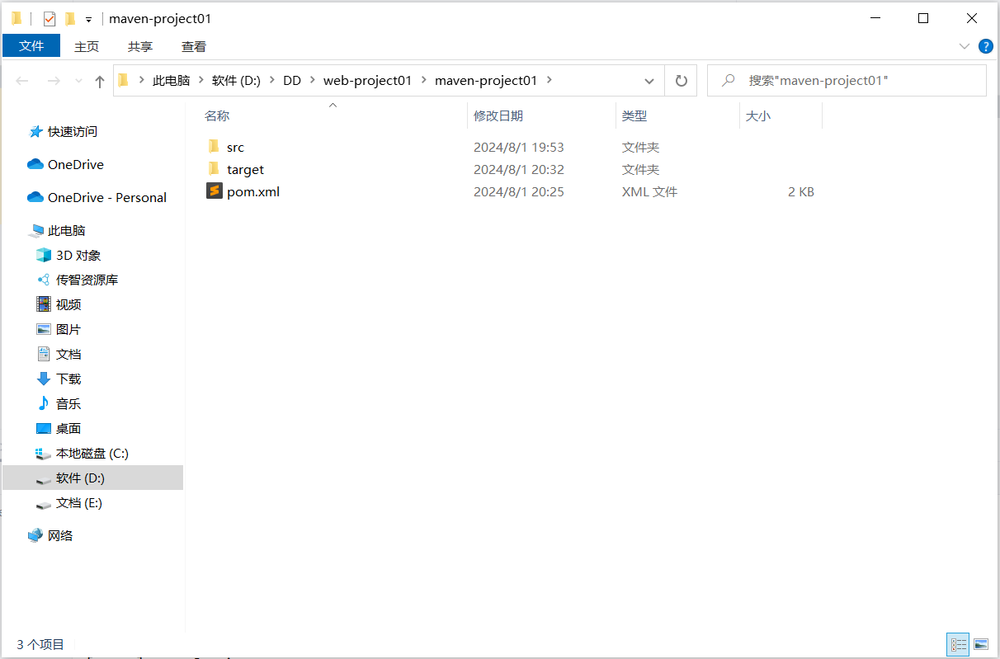

1. 在当前目录下打开CMD

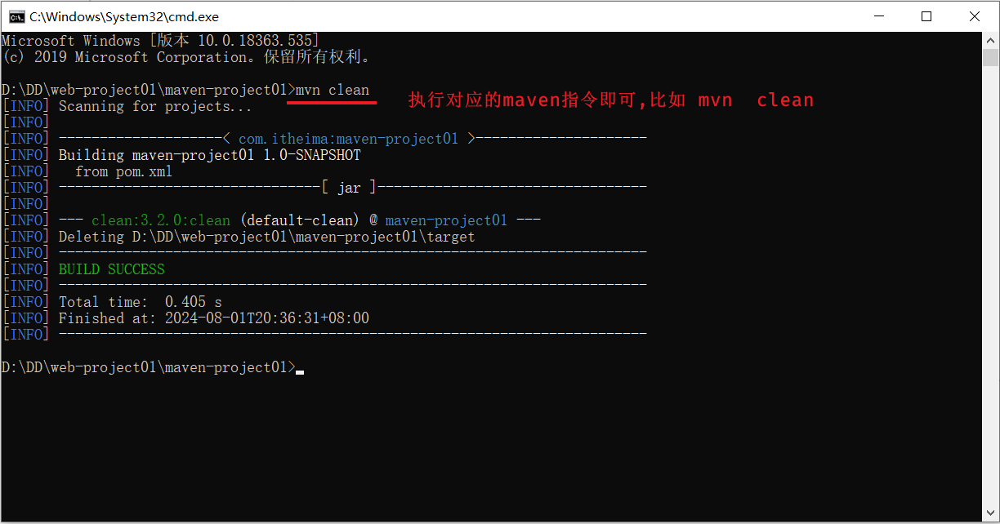

类似的道理，我们也可以在命令执行：

- mvn compile
- mvn test
- mvn package
- mvn install    

**补充：命令与产物对照。**在有 `pom.xml` 的项目/模块目录执行；如果当前目录不是这里，可用 `mvn -f 路径/pom.xml package`。

| 命令 | 本章应观察的结果 |
| --- | --- |
| `mvn clean` | 默认删除 `target`，不清空 Maven 本地仓库 |
| `mvn compile` | 主程序编译到 `target/classes` |
| `mvn test` | 编译主程序与测试程序，执行测试；常见报告目录为 `target/surefire-reports` |
| `mvn package` | 同时经历前面的编译、测试阶段，再生成 `target/*.jar` 等产物 |
| `mvn install` | 在 package 之后，将产物和 POM 安装到本地 Maven 仓库 |
| `mvn clean package` | 先执行 clean 生命周期到 clean，再执行 default 到 package |

`install` 不是给操作系统安装应用；它让本机其他 Maven 项目可以引用这个坐标。普通 Maven JAR 默认不会把所有第三方依赖都塞进包里，也不保证具备 `java -jar` 所需的主类清单；“打包成功”和“可执行应用包”要分别理解。


## 5 单元测试


### 5.1 介绍

<strong>测试：</strong>是一种用来促进鉴定软件的正确性、完整性、安全性和质量的过程。

<strong>阶段划分：</strong>单元测试、集成测试、系统测试、验收测试。

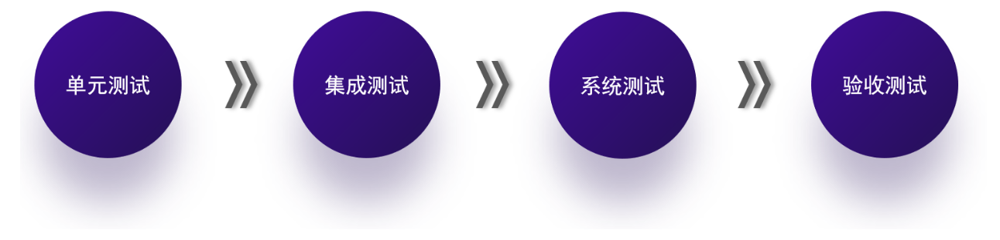

1). 单元测试

- 介绍：对软件的基本组成单位进行测试，最小测试单位。
- 目的：检验软件基本组成单位的正确性。
- 测试人员：开发人员

2). 集成测试

- 介绍：将已分别通过测试的单元，按设计要求组合成系统或子系统，再进行的测试。
- 目的：检查单元之间的协作是否正确。
- 测试人员：开发人员

3). 系统测试

- 介绍：对已经集成好的软件系统进行彻底的测试。
- 目的：验证软件系统的正确性、性能是否满足指定的要求。
- 测试人员：测试人员

4). 验收测试

- 介绍：交付测试，是针对用户需求、业务流程进行的正式的测试。
- 目的：验证软件系统是否满足验收标准。
- 测试人员：客户/需求方

<strong>测试方法：</strong>白盒测试、黑盒测试 及 灰盒测试。

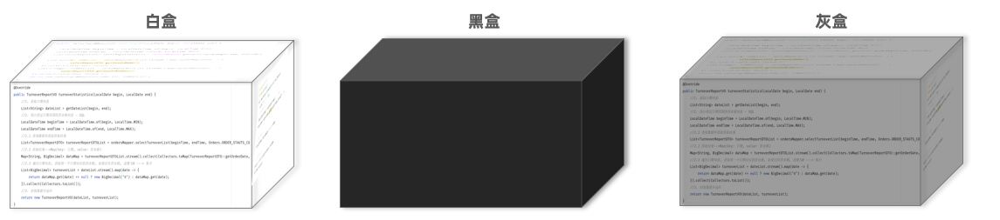

1). 白盒测试

清楚软件内部结构、代码逻辑。

用于验证代码、逻辑正确性。

2). 黑盒测试

不清楚软件内部结构、代码逻辑。

用于验证软件的功能、兼容性、验收测试等方面。

3). 灰盒测试

结合了白盒测试和黑盒测试的特点，既关注软件的内部结构又考虑外部表现（功能）。

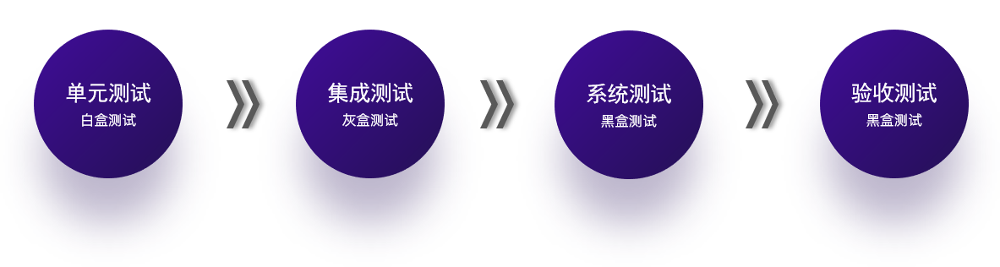


### 5.2 Junit入门


#### 5.2.1 单元测试

- 单元测试：就是针对最小的功能单元(方法)，编写测试代码对其正确性进行测试。
- JUnit：最流行的Java测试框架之一，提供了一些功能，方便程序进行单元测试（第三方公司提供）。

在之前的课程中，我们进行程序的测试 ，都是main方法中进行测试 。如下图所示：

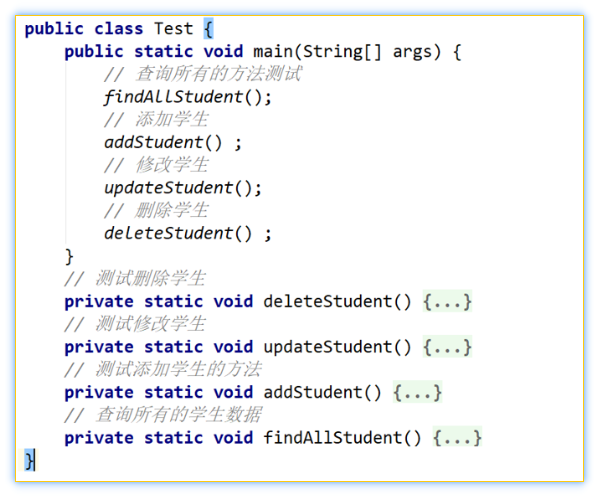

通过<strong>main方法</strong>是可以进行测试的，可以测试程序是否正常运行。但是main方法进行测试时，会存在如下问题：

1. 测试代码与源代码未分开，难维护。
2. 一个方法测试失败，影响后面方法。
3. 无法自动化测试，得到测试报告。

> **补充：**手写 `main` 并非理论上不能自动化，而是要自己编写用例发现、独立执行、断言和报告逻辑。JUnit 已提供这套机制。测试通过只能说明已运行的用例满足断言，不能证明所有输入和场景都正确。

而如果我们使用了<strong>JUnit单元测试</strong>框架进行测试，将会有以下优势：

1. 测试代码与源代码分开，便于维护。
2. 可根据需要进行自动化测试。
3. 可自动分析测试结果，产出测试报告。

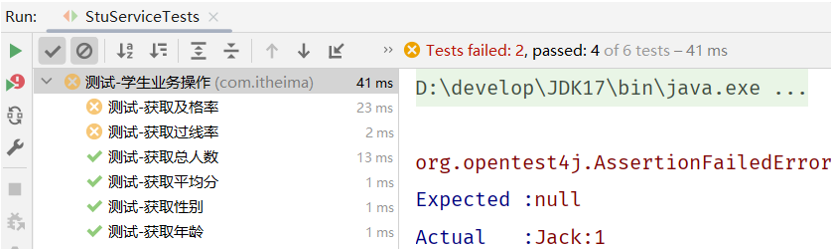


#### 5.2.2 入门程序

需求：使用JUnit，对UserService中的业务方法进行单元测试，测试其正确性。

1. 在<code>pom.xml</code>中，引入JUnit的依赖。

````xml
<!--Junit单元测试依赖-->
<dependency>
    <groupId>org.junit.jupiter</groupId>
    <artifactId>junit-jupiter</artifactId>
    <version>5.9.1</version>
    <scope>test</scope>
</dependency>
````

> **补充：**此处使用 JUnit 5/Jupiter；`@Test` 应导入 `org.junit.jupiter.api.Test`，不要与 JUnit 4 的 `org.junit.Test` 混用。本章正文使用 `5.9.1`，部分截图是 `5.9.2 / 5.9.3`，跟练时统一一个版本即可。依赖添加后先刷新 Maven。

1. 在test/java目录下，创建测试类，并编写对应的测试方法，并在方法上声明@Test注解。

````java
@Test
public void testGetAge(){
    Integer age = new UserService().getAge("110002200505091218");
    System.out.println(age);
}
````

> **补充：**这是一段测试**方法**，需要放进测试类里，并确保主程序中已有 `UserService`。讲义没有在正文给出完整业务类，第 5.6 节补齐了可以直接运行的三个文件。上面的 `println` 只输出年龄；没有断言时，方法未抛异常也会显示绿色，即使计算结果不符合业务预期。

1. 运行单元测试 (测试通过：绿色；测试失败：红色)。

- 测试通过显示绿色

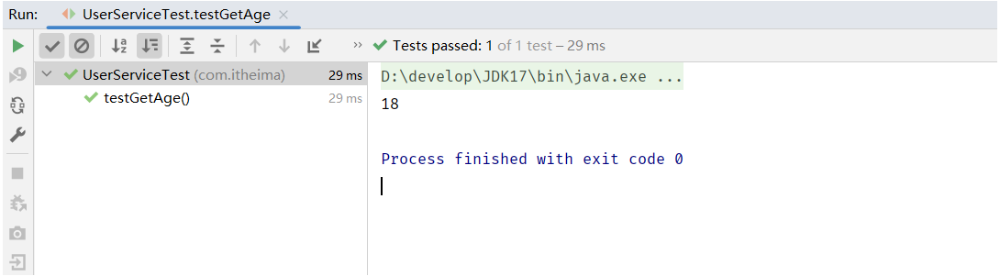

- 测试失败显示红色

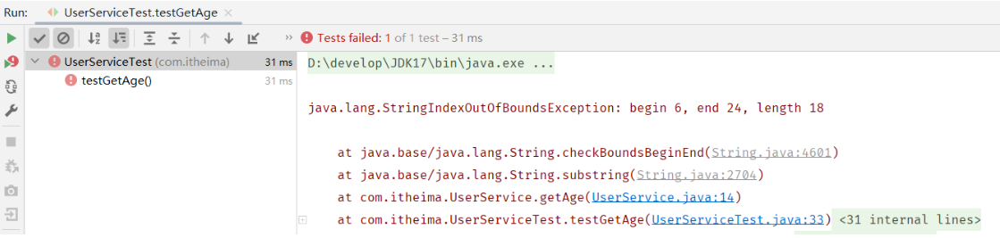

                        

> <strong> 注意：</strong>
> 
> - 测试类的命名规范为：XxxxTest
> - 测试方法的命名规定为：public void xxx(){...}
> 
> > **勘误：**JUnit 5 的测试方法不强制 `public`，包可见方法也支持；通常要求实例方法、非 `private`、非抽象且返回 `void`，普通入门测试不带参数。`XxxxTest` 便于 Maven Surefire 按默认规则发现测试，但不是 JUnit 唯一允许的类名。这里继续用课程的 `public void testXxx()` 风格，便于对照。


### 5.3 断言

JUnit提供了一些辅助方法，用来帮我们确定被测试的方法是否按照预期的效果正常工作，这种方式称为<strong>断言</strong>。

| 断言方法 | 描述 |
| --- | --- |
| assertEquals(Object exp, Object act, String msg) | 检查两个值是否相等，不相等就报错。 |
| assertNotEquals(Object unexp, Object act, String msg) | 检查两个值是否不相等，相等就报错。 |
| assertNull(Object act, String msg) | 检查对象是否为null，不为null，就报错。 |
| assertNotNull(Object act, String msg) | 检查对象是否不为null，为null，就报错。 |
| assertTrue(boolean condition, String msg) | 检查条件是否为true，不为true，就报错。 |
| assertFalse(boolean condition, String msg) | 检查条件是否为false，不为false，就报错。 |
| assertSame(Object exp, Object act, String msg) | 检查两个对象引用是否相等，不相等，就报错。 |

> **补充：**表格是常用重载的简写，最后的错误信息参数通常可省略；JUnit 也为基本类型提供重载。需要断言代码抛出指定异常，可用 `Assertions.assertThrows(IllegalArgumentException.class, () -> 调用方法())`，完整练习会用它检查异常输入。

示例演示：

````java
package com.itheima;

import org.junit.jupiter.api.*;
import org.junit.jupiter.params.ParameterizedTest;
import org.junit.jupiter.params.provider.ValueSource;

public class UserServiceTest {
    
    @Test
    public void testGetAge2(){
        Integer age = new UserService().getAge("110002200505091218");
        Assertions.assertNotEquals(18, age, "两个值相等");
//        String s1 = new String("Hello");
//        String s2 = "Hello";
//        Assertions.assertSame(s1, s2, "不是同一个对象引用");
    }

    @Test
    public void testGetGender2(){
        String gender = new UserService().getGender("612429198904201611");
        Assertions.assertEquals("男", gender);
    }
}
````

> **补充：**`assertNotEquals(18, age)` 只验证“结果不是 18”，无法证明年龄算对了。原例调用当前日期计算年龄，所以截图里的数字不能长期当成固定预期。需要验证正确年龄时，应控制测试日期并断言明确结果；第 5.6 节会覆盖生日前一天、生日当天、生日后一天。
>
> `assertEquals` 检查相等语义；`assertSame` 检查是否为同一个对象引用。两个内容相同的 String 对象可能前者通过、后者失败。断言的 `msg` 在失败时显示，`assertEquals(expected, actual)` 的参数顺序不要颠倒。

测试结果输出：

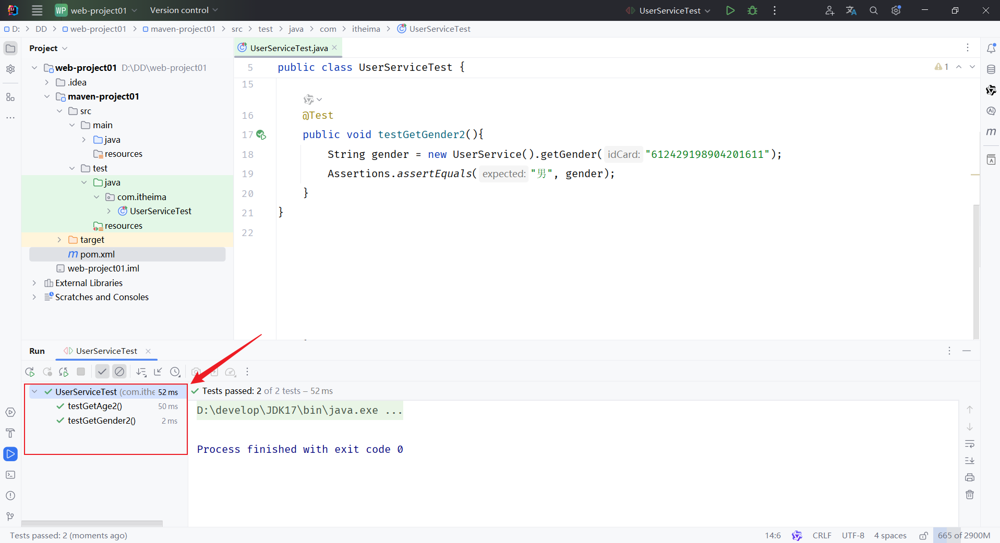


### 5.4 常见注解

在JUnit中还提供了一些注解，还增强其功能，常见的注解有以下几个：

| 注解 | 说明 | 备注 |
| --- | --- | --- |
| @Test | 测试类中的方法用它修饰才能成为测试方法，才能启动执行 | 单元测试 |
| @BeforeEach | 用来修饰一个实例方法，该方法会在每一个测试方法执行之前执行一次。 | 初始化资源(准备工作) |
| @AfterEach | 用来修饰一个实例方法，该方法会在每一个测试方法执行之后执行一次。 | 释放资源(清理工作) |
| @BeforeAll | 用来修饰一个静态方法，该方法会在所有测试方法之前只执行一次。 | 初始化资源(准备工作) |
| @AfterAll | 用来修饰一个静态方法，该方法会在所有测试方法之后只执行一次。 | 释放资源(清理工作) |
| @ParameterizedTest | 参数化测试的注解 (可以让单个测试运行多次，每次运行时仅参数不同) | 用了该注解，就不需要@Test注解了 |
| @ValueSource | 参数化测试的参数来源，赋予测试方法参数 | 与参数化测试注解配合使用 |
| @DisplayName | 指定测试类、测试方法显示的名称 （默认为类名、方法名） |  |

> **补充：**表格中的 `@BeforeAll / @AfterAll` 按本章默认测试实例生命周期解释。参数化测试每个参数都会各自执行一次 `BeforeEach/AfterEach`。这些注解控制测试的准备与清理，不是 Maven 构建生命周期中的阶段。

演示 <code>@BeforeEach</code>，<code>@AfterEach</code>，<code>@BeforeAll</code>，<code>@AfterAll</code> 注解：

````java
public class UserServiceTest {

    @BeforeEach
    public void testBefore(){
        System.out.println("before...");
    }

    @AfterEach
    public void testAfter(){
        System.out.println("after...");
    }

    @BeforeAll //该方法必须被static修饰
    public static void testBeforeAll(){ 
        System.out.println("before all ...");
    }

    @AfterAll //该方法必须被static修饰
    public static void testAfterAll(){
        System.out.println("after all...");
    }

    @Test
    public void testGetAge(){
        Integer age = new UserService().getAge("110002200505091218");
        System.out.println(age);
    }
    
    @Test
    public void testGetGender(){
        String gender = new UserService().getGender("612429198904201611");
        System.out.println(gender);
    }
 }   
````

> **补充：**本段省略了 `package com.itheima;` 和 `import org.junit.jupiter.api.*;`，需要补在文件顶部。前后几段同名 `UserServiceTest` 是不同演示版本，跟练时逐段替换或改类名，不要在同一个包中重复定义同名类。
>
> 本例采用 JUnit 默认的“每个测试方法使用新的测试实例”模式。每次测试的顺序是 `BeforeEach → 测试方法 → AfterEach`，整个类前后各调用一次 `BeforeAll/AfterAll`。默认模式下后两者使用 `static`；显式改用 `@TestInstance(PER_CLASS)` 时允许非静态，入门阶段保持原例即可。测试方法之间的执行顺序不应靠文件中的书写位置推断，也不应互相依赖运行结果。

输出结果如下：

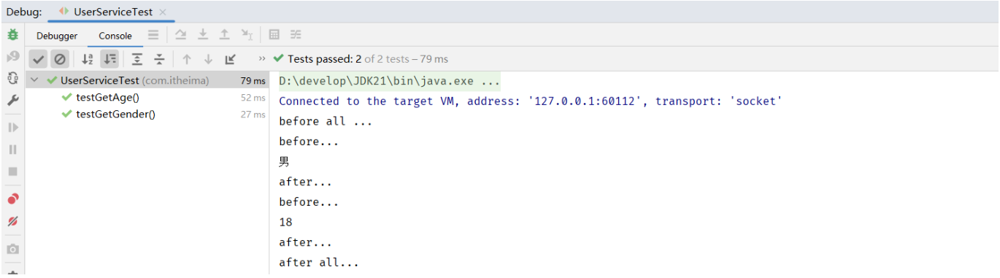

演示 <code>@ParameterizedTest  </code>，<code>@ValueSource</code> ，<code>@DisplayName</code> 注解：

````java
package com.itheima;

import org.junit.jupiter.api.*;
import org.junit.jupiter.params.ParameterizedTest;
import org.junit.jupiter.params.provider.ValueSource;

@DisplayName("测试-学生业务操作")
public class UserServiceTest {

    @DisplayName("测试-获取年龄")
    @Test
    public void testGetAge(){
        Integer age = new UserService().getAge("110002200505091218");
        System.out.println(age);
    }

    @DisplayName("测试-获取性别")
    @Test
    public void testGetGender(){
        String gender = new UserService().getGender("612429198904201611");
        System.out.println(gender);
    }

    @DisplayName("测试-获取性别3")
    @ParameterizedTest
    @ValueSource(strings = {"612429198904201611","612429198904201631","612429198904201626"})
    public void testGetGender3(String idcard){
        String gender = new UserService().getGender(idcard);
         System.out.println(gender);
    }
}
````

> **补充：**`@ValueSource` 中有 3 个字符串，就会为 `testGetGender3` 产生 3 次测试调用，每次将一个值交给形参 `idcard`；不需要再叠加 `@Test`。`@DisplayName` 改的是显示名称，不改变执行逻辑。按讲义的第 17 位奇偶规则，这三个号码预期分别输出“男、男、女”；原例只有打印，若要验证业务正确性，还需要添加对应断言。

输出结果如下：

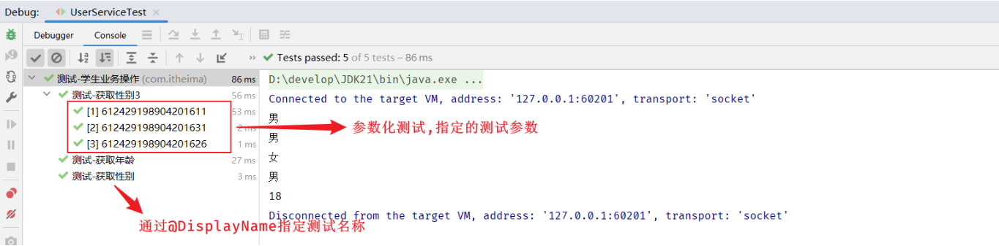

<strong>思考: 在maven项目中，test目录存放单元测试的代码，是否可以在main目录中编写单元测试呢 ？ </strong><strong>可以，但是不规范</strong>

> **勘误：**要分依赖范围看。JUnit 使用本章的 `<scope>test</scope>` 时，`src/main/java` 的编译路径里没有 JUnit，直接在业务类中写 `@Test` 会编译失败。即使把 JUnit 改成 compile 后能通过编译，也不符合本章测试与业务分离的约定，且 Maven 默认在测试输出目录发现测试，因此应放在 `src/test/java`。

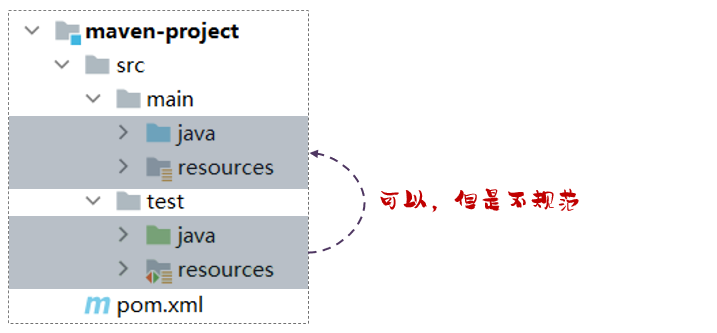


### 5.5 依赖范围

依赖的jar包，默认情况下，可以在任何地方使用，在main目录下，可以使用；在test目录下，也可以使用。 

在maven中，如果希望限制依赖的使用范围，可以通过 <code>&lt;scope&gt;…&lt;/scope&gt;</code> 设置其作用范围。

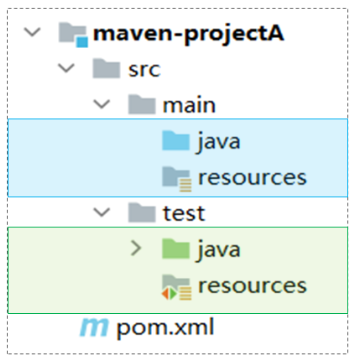

<strong>作用范围：</strong>

- 主程序范围有效。（main文件夹范围内）
- 测试程序范围有效。（test文件夹范围内）
- 是否参与打包运行。（package指令范围内）

可以在pom.xml中配置 <code>&lt;scope&gt;&lt;/scope&gt;</code> 属性来控制依赖范围。

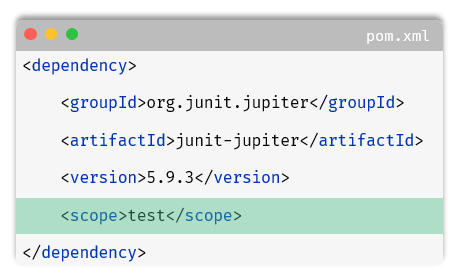

如果对Junit单元测试的依赖，设置了scope为 test，就代表，该依赖，只是在测试程序中可以使用，在主程序中是无法使用的。所以我们会看到如下现象：

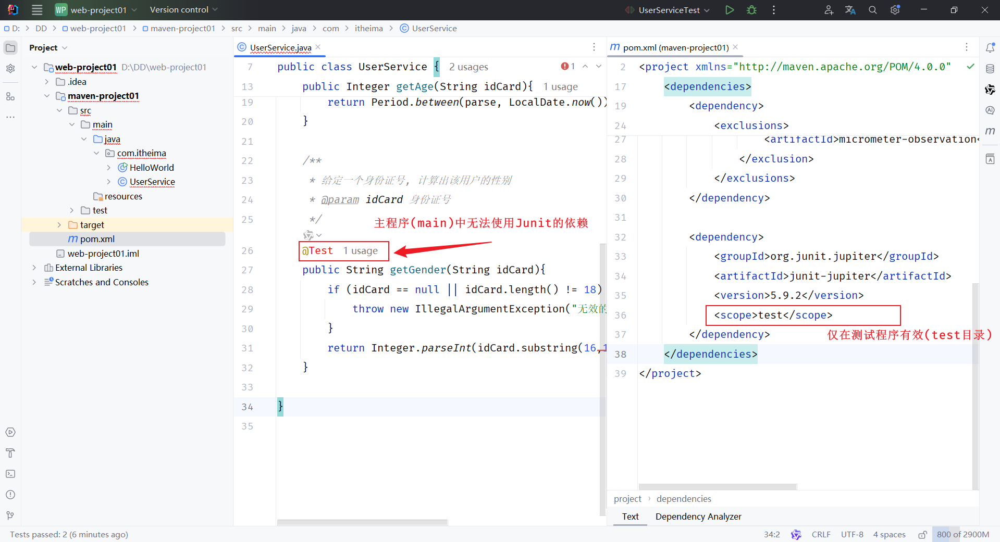

如上图所示，给junit依赖通过scope标签指定依赖的作用范围。 那么这个依赖就只能作用在测试环境，其他环境下不能使用。

scope的取值常见的如下：

| scope值 | 主程序 | 测试程序 | 打包（运行） | 范例 |
| --- | --- | --- | --- | --- |
| compile（默认） | Y | Y | Y | log4j |
| test | - | Y | - | junit |
| provided | Y | Y | - | servlet-api |
| runtime | - | Y | Y | jdbc驱动 |

> **勘误：**表里的“主程序”应理解为主程序**编译时**是否可用；“打包（运行）”主要是在概括运行时 classpath。普通 `jar` 打包不会因为写了 compile 或 runtime 就自动内嵌依赖；WAR、可执行胖 JAR 等由打包类型和插件决定。
>
> - `compile`：默认范围，主程序编译、运行和测试可用。
> - `test`：仅测试编译和测试运行可用；不作为主程序运行依赖传递给下游。
> - `provided`：编译和测试时可用，运行时预期由 JDK/容器等环境提供，例如某些 Servlet 容器提供的 API。
> - `runtime`：主程序编译时不需要，但主程序运行、测试编译与测试运行时需要，例如通过 JDBC 标准 API 使用的驱动。
>
> 表格中的 log4j、servlet-api 是范围示例，不表示本章要求额外安装这些库。


### 5.6 补充：把单元测试案例补成可运行的小项目

原讲义直接调用 `UserService.getAge/getGender`，业务类只在截图中局部出现。下面补齐这两个方法，并把前面介绍的依赖范围、断言、生命周期注解和参数化测试放进一个项目。沿用原例的教学输入字符串，仅演示生日提取与第 17 位奇偶判断；这不是完整的身份证真实性、地区码或校验位验证程序。

**1. 创建目录。**在 IDEA 中创建 Maven 模块，或者按下面的结构保存文件，然后把 `pom.xml` 导入 IDEA。两个 Java 文件的包名与目录保持一致。

```text
maven-junit-demo/
├── pom.xml
└── src/
    ├── main/java/com/itheima/UserService.java
    └── test/java/com/itheima/UserServiceTest.java
```

**2. 项目配置：`pom.xml`。**统一使用讲义正文的 JUnit `5.9.1`，显式固定 Compiler Plugin 与 Surefire Plugin 版本，避免本机默认插件过旧而无法编译 Java 17 或识别 JUnit 5。插件放在 `build/plugins`，JUnit 库放在 `dependencies`。

````xml
<?xml version="1.0" encoding="UTF-8"?>
<project xmlns="http://maven.apache.org/POM/4.0.0"
         xmlns:xsi="http://www.w3.org/2001/XMLSchema-instance"
         xsi:schemaLocation="http://maven.apache.org/POM/4.0.0 https://maven.apache.org/xsd/maven-4.0.0.xsd">
    <modelVersion>4.0.0</modelVersion>
    <groupId>com.itheima</groupId>
    <artifactId>maven-junit-demo</artifactId>
    <version>1.0-SNAPSHOT</version>

    <properties>
        <maven.compiler.release>17</maven.compiler.release>
        <project.build.sourceEncoding>UTF-8</project.build.sourceEncoding>
    </properties>

    <dependencies>
        <dependency>
            <groupId>org.junit.jupiter</groupId>
            <artifactId>junit-jupiter</artifactId>
            <version>5.9.1</version>
            <scope>test</scope>
        </dependency>
    </dependencies>

    <build>
        <plugins>
            <plugin>
                <groupId>org.apache.maven.plugins</groupId>
                <artifactId>maven-compiler-plugin</artifactId>
                <version>3.11.0</version>
            </plugin>
            <plugin>
                <groupId>org.apache.maven.plugins</groupId>
                <artifactId>maven-surefire-plugin</artifactId>
                <version>3.2.5</version>
            </plugin>
        </plugins>
    </build>
</project>
````


**3. 业务类：`src/main/java/com/itheima/UserService.java`。**

号码索引从 0 开始，所以出生日期用 `substring(6, 14)` 取出第 7—14 位，第 17 位用 `charAt(16)` 获取。`Period.between(生日, 今天).getYears()` 计算周岁，避免只用年份相减时忽略生日是否已过。

公开的 `getAge(String)` 按真实日期计算；同包可见的重载 `getAge(String, LocalDate)` 让测试传入固定日期。这只是为测试提供可控制的“今天”，否则写死“年龄应为 18”会随着日期变化失效。非法格式、无效日期和未来生日用异常表达，测试可以验证这些分支。

````java
package com.itheima;

import java.time.LocalDate;
import java.time.Period;
import java.time.format.DateTimeFormatter;
import java.time.format.DateTimeParseException;

public class UserService {
    public Integer getAge(String idCard) {
        return getAge(idCard, LocalDate.now());
    }

    // 同包测试可以传入固定日期，避免年龄断言随真实日期变化。
    Integer getAge(String idCard, LocalDate today) {
        checkFormat(idCard);
        LocalDate birthday;
        try {
            birthday = LocalDate.parse(
                    idCard.substring(6, 14), DateTimeFormatter.BASIC_ISO_DATE);
        } catch (DateTimeParseException e) {
            throw new IllegalArgumentException("出生日期无效", e);
        }
        if (birthday.isAfter(today)) {
            throw new IllegalArgumentException("出生日期不能晚于当前日期");
        }
        return Period.between(birthday, today).getYears();
    }

    public String getGender(String idCard) {
        checkFormat(idCard);
        int sequenceDigit = idCard.charAt(16) - '0';
        return sequenceDigit % 2 == 1 ? "男" : "女";
    }

    private void checkFormat(String idCard) {
        if (idCard == null || !idCard.matches("[0-9]{17}[0-9Xx]")) {
            throw new IllegalArgumentException("需要18位教学用号码");
        }
    }
}
````


**4. 测试类：`src/test/java/com/itheima/UserServiceTest.java`。**

每次测试前创建独立的业务对象，避免依赖上一条测试的状态。先验证生日边界，再验证两种性别结果，最后验证异常输入。`assertThrows` 的第一个参数是预期异常类型，第二个参数是待执行的代码。

````java
package com.itheima;

import java.time.LocalDate;
import org.junit.jupiter.api.*;
import org.junit.jupiter.params.ParameterizedTest;
import org.junit.jupiter.params.provider.ValueSource;

@DisplayName("UserService 单元测试")
public class UserServiceTest {
    private UserService service;

    @BeforeAll
    public static void beforeAll() {
        System.out.println("before all ...");
    }

    @BeforeEach
    public void beforeEach() {
        service = new UserService();
        System.out.println("before...");
    }

    @AfterEach
    public void afterEach() {
        System.out.println("after...");
    }

    @AfterAll
    public static void afterAll() {
        System.out.println("after all ...");
    }

    @Test
    @DisplayName("生日之前、当天、之后的周岁")
    public void testAgeAroundBirthday() {
        String idCard = "110002200505091218";
        Assertions.assertEquals(20,
                service.getAge(idCard, LocalDate.of(2026, 5, 8)).intValue());
        Assertions.assertEquals(21,
                service.getAge(idCard, LocalDate.of(2026, 5, 9)).intValue());
        Assertions.assertEquals(21,
                service.getAge(idCard, LocalDate.of(2026, 5, 10)).intValue());
    }

    @ParameterizedTest
    @ValueSource(strings = {"612429198904201611", "612429198904201631"})
    @DisplayName("第17位为奇数")
    public void testMale(String idCard) {
        Assertions.assertEquals("男", service.getGender(idCard));
    }

    @Test
    @DisplayName("第17位为偶数")
    public void testFemale() {
        Assertions.assertEquals("女", service.getGender("612429198904201626"));
    }

    @Test
    @DisplayName("拒绝空值和长度错误")
    public void testInvalidFormat() {
        Assertions.assertThrows(IllegalArgumentException.class,
                () -> service.getGender(null));
        Assertions.assertThrows(IllegalArgumentException.class,
                () -> service.getAge("123"));
    }

    @Test
    @DisplayName("拒绝不存在的出生日期")
    public void testInvalidBirthday() {
        Assertions.assertThrows(IllegalArgumentException.class,
                () -> service.getAge("110002200502301218",
                        LocalDate.of(2026, 5, 9)));
    }

    @Test
    @DisplayName("拒绝未来出生日期")
    public void testFutureBirthday() {
        Assertions.assertThrows(IllegalArgumentException.class,
                () -> service.getAge("110002203005091218",
                        LocalDate.of(2026, 5, 9)));
    }
}
````

**5. 运行与观察。**先 Reload Maven Project，也可以直接在这个项目的 `pom.xml` 所在目录运行：

```text
mvn test
```

这里共有 7 次测试执行，其中 `testMale` 的两个输入分别算一次。预期汇总为 `Tests run: 7, Failures: 0, Errors: 0, Skipped: 0`。`before all / after all` 各出现一次，`before / after` 每次测试各出现一次；不同测试方法的前后顺序不作为断言。

若希望从头编译、测试并打包，执行：

```text
mvn clean package
```

检查这些输出：

| 位置/输出 | 含义 |
| --- | --- |
| `BUILD SUCCESS` | 本次 Maven 构建的阶段成功完成 |
| `target/classes/com/itheima/UserService.class` | 业务类编译产物 |
| `target/test-classes/com/itheima/UserServiceTest.class` | 测试类编译产物 |
| `target/surefire-reports` | 文本与 XML 测试报告 |
| `target/maven-junit-demo-1.0-SNAPSHOT.jar` | 普通业务 JAR，不含测试类，也未配置可执行主类 |

只看 `BUILD SUCCESS` 还不够：同时检查测试数量是否为 7，避免测试没有被发现时误以为“所有测试都通过了”。也可以临时把第一个年龄预期从 `20` 改成 `19`，观察断言失败信息，再恢复正确值。这个练习只构建本地项目，不需要执行 `deploy`。


## 6 Maven常见问题

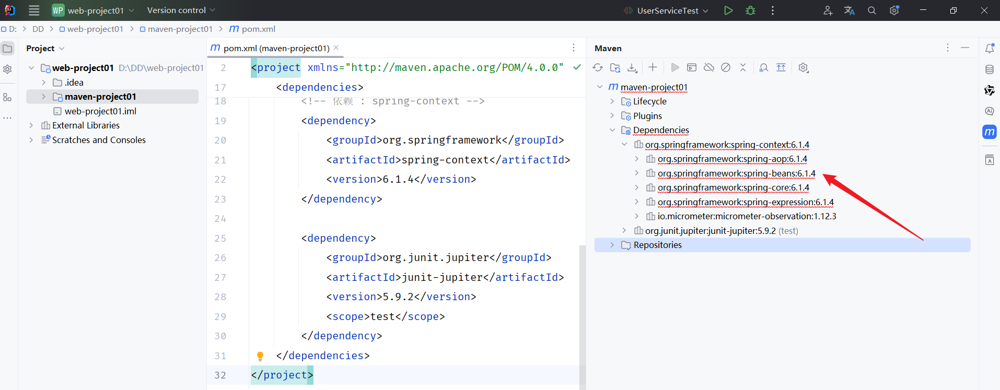

- <strong>问题现象：</strong>Maven项目中添加的依赖，未正确下载，造成右侧Maven面板中的依赖报红，再次reload重新加载也不会再下载。
- <strong>产生原因：</strong>由于网络原因，依赖没有下载完整导致的，在maven仓库中生成了<strong>xxx.lastUpdated</strong>文件，该文件不删除，不会再重新下载。

> **勘误：**`.lastUpdated` 记录依赖解析失败及检查时间。Maven 可能按仓库更新策略暂时不重试，并非“不删除就永远不能再下载”。先修复网络、镜像地址、代理或坐标错误，再尝试 `mvn -U test` 强制检查缺失发布版和更新快照；还不行时再针对报错坐标清理失败记录。

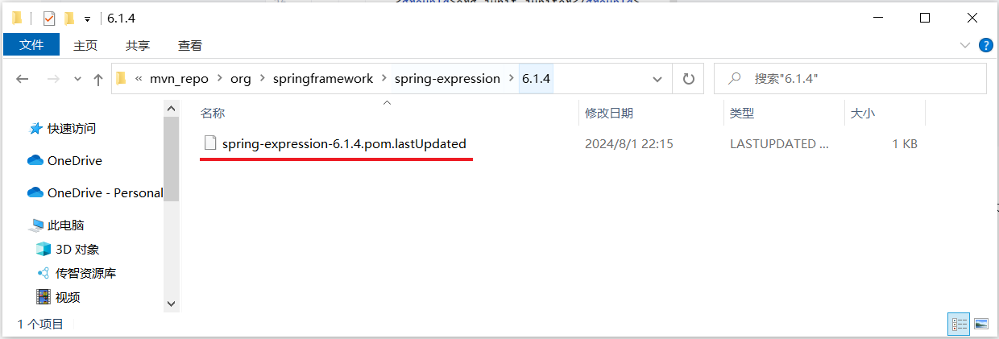

<strong>解决方案：</strong>

1. 根据maven依赖的坐标，找到仓库中对应的 xxx.lastUpdated 文件，删除，删除之后重新加载项目即可。
2. 通过命令 (del /s &#42;.lastUpdated) 批量递归删除指定目录下的 xxx.lastUpdated 文件，删除之后重新加载项目即可。
3. 重新加载依赖，依赖下载了之后，maven面板可能还会报红，此时可以关闭IDEA，重新打开IDEA加载此项目即可。

为了使大家能够方便的解决这个问题，大家可以将资料中提供的 del.bat 批处理脚本，拷贝到maven的安装目录下。 双击这个文件，就可以递归删除该目录下所有的 xxx.lastUpdated 文件。 放置目录如下所示：

> **勘误：**课程把本地仓库放在 Maven 安装目录内，所以把脚本放在那里才会搜索到仓库文件。若仓库另设在 `D:/develop/maven-repository`，就要定位这个实际仓库目录；脚本不会读取 `settings.xml` 自动寻找仓库。
>
> **补充：**`del /s *.lastUpdated` 是 **CMD** 命令，递归范围由当前目录决定。应先在资源管理器确认报错坐标对应的具体目录，优先只删除该目录内的失败记录。不要在磁盘根目录或项目根目录随意批量执行；PowerShell 的 `del` 是另一个命令的别名，不能照抄 CMD 参数。

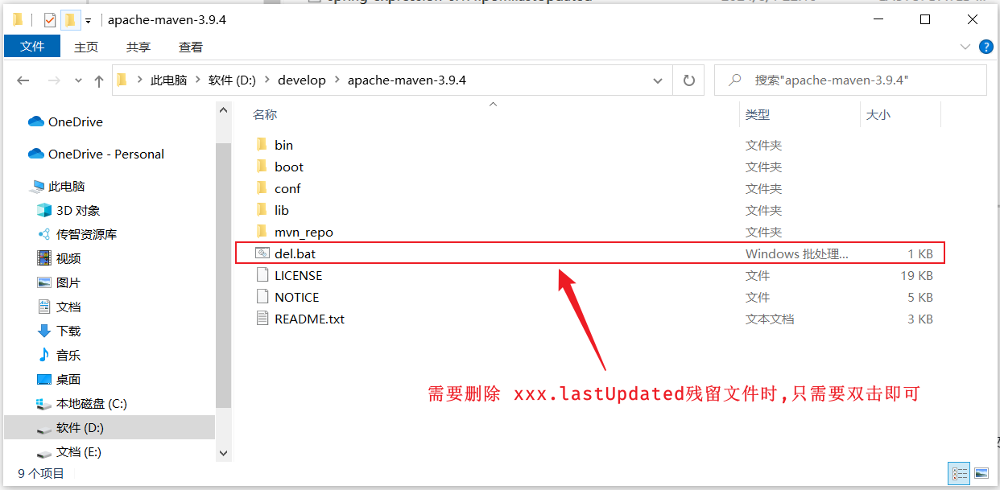

- <strong>附件（上述提到的del.bat批处理文件， 也可以直接点此下载）：</strong>

**讲义附件：**[del.bat](https://heuqqdmbyk.feishu.cn/space/api/box/stream/download/all/JdIMbcrdxoSlTTxfhOdcFJwQnOc/)

**附件内容转写：**

````bat
del /s *.lastUpdated
````

附件只有这一条命令。`/s` 表示递归搜索当前目录及子目录；`*.lastUpdated` 只匹配这类后缀的记录文件。先确认当前目录和实际 Maven 本地仓库的位置，再决定是否需要处理。


### 6.1 补充：按报错位置排查

| 现象 | 先核对什么 |
| --- | --- |
| 找不到 `mvn` 命令 | Maven 解压位置、Path 中的 bin、新终端是否加载环境变量 |
| `JAVA_HOME` 不正确，或提示缺少编译器 | JDK 是否完整安装；`mvn -v` 显示的 Java home 是否符合预期 |
| 提示当前目录没有 POM | 进入实际 Maven 模块目录，或用 `-f` 指定 POM |
| `release version 17 not supported` 等版本错误 | 运行 Maven 的 JDK 是否支持 17；IDEA 与终端是否使用不同 JDK |
| IDEA 正常，命令行失败，或反过来 | Maven 版本、settings.xml、本地仓库、JDK 是否一致 |
| 依赖持续下载失败 | 坐标是否存在、网络/代理/镜像是否可用、是否开启离线模式，再检查 lastUpdated 记录 |
| 主程序找不到 JUnit 的 `@Test` | 测试代码是否误放在 main；不要为了绕过报错而随意把 test 范围改成 compile |
| `Tests run: 0` | 测试类位置、类名后缀、JUnit 5 导入，以及 Surefire 插件是否支持 Jupiter |
| 测试绿色但结果不对 | 是否只有 println，是否真正断言了业务预期 |
| 断言随日期变化而失败 | 是否把当前年龄写死；对时间相关逻辑使用可控制的测试日期 |
| JAR 不能用 `java -jar` 运行 | 是否只是普通库 JAR，是否配置主类及运行依赖 |

核对本章勘误所用的官方说明：[Maven 生命周期](https://maven.apache.org/guides/introduction/introduction-to-the-lifecycle.html)、[依赖机制与范围](https://maven.apache.org/guides/introduction/introduction-to-dependency-mechanism.html)、[settings.xml](https://maven.apache.org/settings.html)、[JUnit 5.9.1 用户指南](https://docs.junit.org/5.9.1/user-guide/)。
